# IA y empleo en Perú: ENAHO 2022

Versión anual final del cruce entre ENAHO y el índice ocupacional de exposición a IA. Este cuaderno replica la lógica del HTML maestro, pero concentrada en un solo año y con salidas desagregadas para auditoría y revisión.

## Alcance

- Año analizado: **2022**
- Base laboral: **ENAHO anual, ocupados**
- Índice: **Claude Sonnet 4-6 / abril 2026**
- Clasificación ocupacional: **CNO-2015 a 4 dígitos**
- Este cuaderno está pensado como versión final reproducible del corte anual, alineada con el HTML maestro.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from IPython.display import HTML, display

try:
    import plotly.express as px
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    HAS_PLOTLY = True
except ModuleNotFoundError:
    px = None
    go = None
    make_subplots = None
    HAS_PLOTLY = False

try:
    from scipy.stats import kruskal, spearmanr
    HAS_SCIPY = True
except ModuleNotFoundError:
    kruskal = None
    spearmanr = None
    HAS_SCIPY = False

def locate_project_root():
    cwd = Path.cwd().resolve()
    for candidate in (cwd, *cwd.parents):
        if (candidate / "_interno").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError(
        "No se encontró la raíz de ia_empleo_peru desde el directorio actual."
    )

def require_path(path, label):
    if not path.exists():
        raise FileNotFoundError(f"Falta {label}: {path}")
    return path

ANALYSIS_YEAR = 2022
PROJECT_ROOT = locate_project_root()
INTERNAL_ROOT = PROJECT_ROOT / "_interno"
BASE_CSV_PATH = require_path(
    INTERNAL_ROOT / "bases" / "intermedias" / "enaho_complete_years" / "ENAHO_complete_2022.csv",
    "base ENAHO completa del año",
)
INDEX_PATH = require_path(
    INTERNAL_ROOT / "referencias" / "indices" / "anthropic-claude-sonnet-4-6_exposure_index.xlsx",
    "índice de exposición",
)
REPORT_PATH = require_path(
    INTERNAL_ROOT / "outputs" / f"enaho_exposure_{ANALYSIS_YEAR}" / f"enaho_exposure_{ANALYSIS_YEAR}_occupation_report.xlsx",
    "reporte anual consolidado",
)
PROCESSED_DIR = require_path(
    INTERNAL_ROOT / "bases" / "procesadas",
    "bases procesadas",
)
OUTPUT_DIR = INTERNAL_ROOT / "outputs" / f"enaho_exposure_{ANALYSIS_YEAR}"
OUTPUT_TABLES = OUTPUT_DIR / "annual_tables"
OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)

PROFILE_SHEETS = [
    "sexo",
    "educacion",
    "categoria",
    "categoria_agregada",
    "grupo_edad",
    "formalidad_contrato",
    "formalidad_tamano",
    "rama",
    "estrato",
]
PROFILE_LABELS = {
    "sexo": "Sexo",
    "educacion": "Educación",
    "categoria": "Categoría ocupacional",
    "categoria_agregada": "Categoría agregada",
    "grupo_edad": "Grupo de edad",
    "formalidad_contrato": "Contrato",
    "formalidad_tamano": "Tamaño de empresa",
    "rama": "Rama de actividad",
    "estrato": "Estrato",
    "internet_uso": "Uso de internet en el trabajo",
    "internet_frecuencia": "Frecuencia de uso de internet en el trabajo",
}
PERSONA_REGIONS = [(15, "Lima"), (4, "Arequipa"), (13, "La Libertad"), (7, "Callao")]
DEPT_NAMES = {
    1: "Amazonas",
    2: "Ancash",
    3: "Apurímac",
    4: "Arequipa",
    5: "Ayacucho",
    6: "Cajamarca",
    7: "Callao",
    8: "Cusco",
    9: "Huancavelica",
    10: "Huánuco",
    11: "Ica",
    12: "Junín",
    13: "La Libertad",
    14: "Lambayeque",
    15: "Lima",
    16: "Loreto",
    17: "Madre de Dios",
    18: "Moquegua",
    19: "Pasco",
    20: "Piura",
    21: "Puno",
    22: "San Martín",
    23: "Tacna",
    24: "Tumbes",
    25: "Ucayali",
}
CAT_MAP = {
    1: "Empleador/a",
    2: "Independiente",
    3: "Empleado/a",
    4: "Obrero/a",
    5: "Familiar no remunerado/a",
    6: "Trab. del hogar",
    7: "Otro",
}
EDU_MAP = {
    1: "sin nivel",
    2: "educación inicial",
    3: "primaria incompleta",
    4: "primaria completa",
    5: "secundaria incompleta",
    6: "secundaria completa",
    7: "superior no universitaria incompleta",
    8: "superior no universitaria completa",
    9: "superior universitaria incompleta",
    10: "superior universitaria completa",
    11: "maestría/doctorado",
    12: "básica especial",
}
MAJOR_GROUP_MAP = {
    "0": "Ocupaciones militares",
    "1": "Directores y gerentes",
    "2": "Profesionales científicos e intelectuales",
    "3": "Técnicos y profesionales de nivel medio",
    "4": "Personal administrativo de apoyo",
    "5": "Trabajadores de servicios y vendedores",
    "6": "Trabajadores agropecuarios, forestales y pesqueros",
    "7": "Oficiales, operarios y artesanos",
    "8": "Operadores de instalaciones y maquinaria",
    "9": "Ocupaciones elementales",
}
COLORS = {
    "accent": "#c25b2a",
    "accent2": "#2563eb",
    "accent3": "#059669",
    "yellow": "#d97706",
    "purple": "#7c3aed",
    "teal": "#0891b2",
    "text": "#1a1a1a",
    "muted": "#6b7280",
    "border": "#e5e7eb",
    "bg": "#f8f8f6",
    "card": "#ffffff",
    "slate": "#94a3b8",
}

METRIC_SPECS = [
    ("mean_exposure_score", "Exposición media", COLORS["accent"]),
    ("%_media_alta_exp", "% media/alta exposición", COLORS["accent2"]),
    ("%_alta_exposicion", "% alta exposición", COLORS["teal"]),
    ("%_aumento", "% aumento", COLORS["accent3"]),
    ("%_sustitucion", "% sustitución", COLORS["yellow"]),
]

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 160)
if HAS_PLOTLY:
    px.defaults.template = "plotly_white"

CSS = f"""
<style>
body {{ background:{COLORS["bg"]}; }}
.jp-Cell-inputWrapper, .jp-InputArea, .jp-InputPrompt,
div.input, div.input_area, .input_prompt {{
    display:none !important;
}}
.audit-grid {{ display:grid; grid-template-columns:repeat(auto-fit,minmax(180px,1fr)); gap:12px; margin:8px 0 20px 0; }}
.audit-card {{ background:{COLORS["card"]}; border:1px solid {COLORS["border"]}; border-radius:14px; padding:14px 16px; }}
.audit-card .eyebrow {{ font-size:11px; text-transform:uppercase; letter-spacing:.08em; color:{COLORS["muted"]}; }}
.audit-card .value {{ font-size:30px; font-weight:700; color:{COLORS["accent"]}; margin-top:4px; }}
.audit-card .sub {{ font-size:12px; color:{COLORS["muted"]}; margin-top:3px; }}
.audit-note {{ background:#fffbf5; border-left:4px solid {COLORS["yellow"]}; border-radius:0 10px 10px 0; padding:12px 16px; margin:14px 0; color:#78350f; }}
.audit-note.blue {{ background:#eff6ff; border-left-color:{COLORS["accent2"]}; color:#1e3a8a; }}
.audit-note.green {{ background:#f0fdf4; border-left-color:{COLORS["accent3"]}; color:#14532d; }}
.mini-tag {{ display:inline-block; padding:2px 8px; border-radius:999px; background:#f3f4f6; color:{COLORS["muted"]}; font-size:11px; margin-right:6px; }}
</style>
"""
display(HTML(CSS))

def safe_zfill(series):
    return pd.to_numeric(series, errors="coerce").astype("Int64").astype("string").str.zfill(4)

def normalize_group_labels(series, fill_value="Sin dato"):
    clean = pd.Series(series, copy=False).astype("string").str.strip()
    clean = clean.replace({"<NA>": fill_value, "nan": fill_value, "None": fill_value, "": fill_value})
    return clean.fillna(fill_value)

def weighted_mean(values, weights):
    v = pd.to_numeric(values, errors="coerce")
    w = pd.to_numeric(weights, errors="coerce")
    mask = v.notna() & w.notna() & (w > 0)
    if not mask.any():
        return np.nan
    return float(np.average(v[mask], weights=w[mask]))

def weighted_share(mask, weights):
    return weighted_mean(pd.Series(mask).astype(float), weights)

def weighted_median(values, weights):
    return weighted_quantile(values, weights, 0.5)

def weighted_quantile(values, weights, quantiles):
    v = pd.to_numeric(values, errors="coerce")
    w = pd.to_numeric(weights, errors="coerce")
    mask = v.notna() & w.notna() & (w > 0)
    if not mask.any():
        if np.isscalar(quantiles):
            return np.nan
        return np.full(len(np.atleast_1d(quantiles)), np.nan)
    ordered = pd.DataFrame({"value": v[mask], "weight": w[mask]}).sort_values("value")
    cumulative = ordered["weight"].cumsum() / ordered["weight"].sum()
    q = np.atleast_1d(np.asarray(quantiles, dtype=float))
    out = np.interp(q, cumulative.to_numpy(), ordered["value"].to_numpy())
    return float(out[0]) if np.isscalar(quantiles) else out

def build_group_summary(df, group_col, weight_col="factor"):
    valid = df[[group_col, weight_col, "mean_exposure_score", "%_media_alta_exp", "%_alta_exposicion", "%_aumento", "%_sustitucion"]].copy()
    valid = valid[valid["mean_exposure_score"].notna()].copy()
    valid[group_col] = normalize_group_labels(valid[group_col])
    grouped = (
        valid.groupby(group_col, dropna=False)
        .apply(
            lambda g: pd.Series(
                {
                    "weighted_population": g[weight_col].sum(),
                    "mean_exposure_score": weighted_mean(g["mean_exposure_score"], g[weight_col]),
                    "pct_media_alta_exp": weighted_mean(g["%_media_alta_exp"], g[weight_col]),
                    "pct_alta_exposicion": weighted_mean(g["%_alta_exposicion"], g[weight_col]),
                    "pct_aumento": weighted_mean(g["%_aumento"], g[weight_col]),
                    "pct_sustitucion": weighted_mean(g["%_sustitucion"], g[weight_col]),
                }
            ),
            include_groups=False,
        )
        .reset_index()
        .rename(columns={group_col: "group"})
    )
    if not grouped.empty:
        grouped["population_share"] = grouped["weighted_population"] / grouped["weighted_population"].sum()
    else:
        grouped["population_share"] = pd.Series(dtype=float)
    return grouped.sort_values("weighted_population", ascending=False).reset_index(drop=True)

def build_weighted_box_table(df, dimension_specs, metric_specs, weight_col="factor"):
    rows = []
    for col, dim_label in dimension_specs:
        sub = df[[col, weight_col] + [metric for metric, _, _ in metric_specs]].copy()
        sub[col] = normalize_group_labels(sub[col])
        for group_name, group_df in sub.groupby(col, dropna=False):
            weight_sum = pd.to_numeric(group_df[weight_col], errors="coerce").fillna(0).sum()
            if weight_sum <= 0:
                continue
            for metric_col, metric_label, _ in metric_specs:
                values = pd.to_numeric(group_df[metric_col], errors="coerce")
                weights = pd.to_numeric(group_df[weight_col], errors="coerce")
                mask = values.notna() & weights.notna() & (weights > 0)
                if mask.sum() == 0:
                    continue
                p05, p25, p50, p75, p95 = weighted_quantile(values[mask], weights[mask], [0.05, 0.25, 0.5, 0.75, 0.95])
                rows.append(
                    {
                        "dimension": col,
                        "dimension_label": dim_label,
                        "group": str(group_name),
                        "metric": metric_col,
                        "metric_label": metric_label,
                        "weighted_population": float(weight_sum),
                        "p05": float(p05),
                        "p25": float(p25),
                        "p50": float(p50),
                        "p75": float(p75),
                        "p95": float(p95),
                    }
                )
    return pd.DataFrame(rows)

def build_distribution_summary(df, metric_specs, weight_col):
    rows = []
    for metric_col, metric_label, _ in metric_specs:
        valid = df[[metric_col, weight_col]].dropna().copy()
        valid[weight_col] = pd.to_numeric(valid[weight_col], errors="coerce")
        valid = valid[valid[weight_col] > 0].copy()
        if valid.empty:
            continue
        q10, q25, q50, q75, q90 = weighted_quantile(valid[metric_col], valid[weight_col], [0.10, 0.25, 0.50, 0.75, 0.90])
        rows.append(
            {
                "metric": metric_col,
                "metric_label": metric_label,
                "mean_weighted": weighted_mean(valid[metric_col], valid[weight_col]),
                "p10": float(q10),
                "p25": float(q25),
                "p50": float(q50),
                "p75": float(q75),
                "p90": float(q90),
            }
        )
    return pd.DataFrame(rows)

def build_cumulative_curve(df, metric_col, metric_label):
    ordered = df[["code", "occupation_group", "weighted_population", metric_col]].dropna().copy()
    ordered = ordered[ordered["weighted_population"] > 0].sort_values(metric_col, ascending=False).reset_index(drop=True)
    if ordered.empty:
        return ordered
    ordered["metric_mass"] = ordered["weighted_population"] * ordered[metric_col]
    total_pop = ordered["weighted_population"].sum()
    total_mass = ordered["metric_mass"].sum()
    ordered["cum_population_share"] = ordered["weighted_population"].cumsum() / total_pop
    ordered["cum_metric_share"] = ordered["metric_mass"].cumsum() / total_mass if total_mass > 0 else np.nan
    ordered["metric"] = metric_col
    ordered["metric_label"] = metric_label
    return ordered

def fmt_pct(value, digits=1):
    if pd.isna(value):
        return "N/D"
    return f"{value * 100:.{digits}f}%"

def fmt_num(value):
    if pd.isna(value):
        return "N/D"
    return f"{value:,.0f}"

def fmt_sol(value):
    if pd.isna(value):
        return "N/D"
    return f"S/ {value:,.0f}"

def render_cards(cards):
    html = ['<div class="audit-grid">']
    for card in cards:
        html.append(
            "<div class='audit-card'>"
            f"<div class='eyebrow'>{card['label']}</div>"
            f"<div class='value'>{card['value']}</div>"
            f"<div class='sub'>{card['sub']}</div>"
            "</div>"
        )
    html.append("</div>")
    display(HTML("".join(html)))

def render_note(text, tone="amber"):
    klass = "audit-note"
    if tone == "blue":
        klass += " blue"
    elif tone == "green":
        klass += " green"
    display(HTML(f"<div class='{klass}'>{text}</div>"))

def show_plotly(fig, include_js=False):
    if HAS_PLOTLY and fig is not None:
        display(HTML(fig.to_html(full_html=False, include_plotlyjs="cdn" if include_js else False)))

In [2]:
report_xl = pd.ExcelFile(REPORT_PATH)
report = {sheet: report_xl.parse(sheet) for sheet in report_xl.sheet_names}
occupation_summary = report["occupation_summary"].copy()
occupation_summary["code"] = occupation_summary["code"].astype(str).str.zfill(4)
occupation_summary = occupation_summary.sort_values("weighted_population", ascending=False).reset_index(drop=True)
occupation_summary["occupation_label"] = occupation_summary["code"] + " · " + occupation_summary["occupation_group"].astype(str)
occupation_summary["major_group_code"] = occupation_summary["code"].str[0]
occupation_summary["major_group"] = occupation_summary["major_group_code"].map(MAJOR_GROUP_MAP).fillna("Otros")
occupation_summary["workers_millions"] = occupation_summary["weighted_population"] / 1_000_000
occupation_summary["balance_aumento_sustitucion"] = occupation_summary["pct_aumento"] - occupation_summary["pct_sustitucion"]
coverage = report["coverage"].iloc[0].to_dict()
profiles = {sheet: report[sheet].copy() for sheet in PROFILE_SHEETS if sheet in report}

top_occ = (
    occupation_summary[occupation_summary["weighted_population"] > 50000]
    .nlargest(20, "mean_exposure_score")
    .copy()
)
exposure_q75_occ = weighted_quantile(
    occupation_summary["mean_exposure_score"],
    occupation_summary["weighted_population"],
    0.75,
)
top_exposed_mass = (
    occupation_summary[occupation_summary["mean_exposure_score"] >= exposure_q75_occ]
    .sort_values("weighted_population", ascending=False)
    .head(15)
    .copy()
)
bubble_df = occupation_summary[occupation_summary["weighted_population"] >= 80000].copy()
bubble_df["women_pct"] = bubble_df["share_women"] * 100
transform_df = occupation_summary[occupation_summary["weighted_population"] >= 50000].copy()

idx = pd.read_excel(INDEX_PATH)
idx["code"] = safe_zfill(idx["code"])
idx = idx[
    [
        "code",
        "occupation_group",
        "mean_exposure_score",
        "median_exposure_score",
        "%_alta_exposicion",
        "%_media_alta_exp",
        "%_sustitucion",
        "%_aumento",
    ]
].copy()

base = pd.read_csv(BASE_CSV_PATH, low_memory=False)
if "year" in base.columns:
    base = base[base["year"] == ANALYSIS_YEAR].copy()
if "ocu500" in base.columns:
    base["ocu500"] = pd.to_numeric(base["ocu500"], errors="coerce")
    base = base[base["ocu500"] == 1].copy()
base["factor"] = pd.to_numeric(base["factor"], errors="coerce").fillna(0)
base = base[base["factor"] > 0].copy()
base["occupation_code_4d"] = safe_zfill(base["ocupación del trabajador"])
base["age"] = pd.to_numeric(base["edad del trabajador"], errors="coerce")
base_merged = base.merge(idx, how="left", left_on="occupation_code_4d", right_on="code")
matched_base = base_merged[base_merged["mean_exposure_score"].notna()].copy()

matched_base["sex_label"] = normalize_group_labels(matched_base["sexo del trabajador"])
matched_base["education_label_base"] = normalize_group_labels(matched_base["nivel educativo"])
matched_base["category_detail_label"] = normalize_group_labels(matched_base["categoría ocupacional"])
matched_base["category_group_label"] = matched_base["category_detail_label"].replace(
    {
        "empleador o patrono": "Empleador / dueño",
        "independiente": "Independiente",
        "empleado": "Asalariado",
        "obrero": "Asalariado",
        "trabajador familiar no remunerado": "Familiar no remunerado",
        "trabajador del hogar": "Trabajador del hogar",
        "otro": "Otro",
    }
)
matched_base["contract_label"] = normalize_group_labels(matched_base["formalidad laboral (contrato)"])
matched_base["firm_size_label"] = normalize_group_labels(matched_base["formalidad laboral (tamaño empresa)"])
matched_base["strata_label"] = normalize_group_labels(matched_base["estrato"])
matched_base["rama_label"] = normalize_group_labels(matched_base["rama_clasif"])
matched_base["internet_use_label"] = normalize_group_labels(matched_base["uso de internet en trabajo"]).replace(
    {
        "el trabajo": "usa internet en el trabajo",
        "pase": "no usa internet en el trabajo",
    }
)
matched_base["internet_use_label"] = matched_base["internet_use_label"].replace({"Sin dato": "sin dato"})
matched_base["internet_frequency_label"] = normalize_group_labels(matched_base["frecuencia uso internet"])
matched_base.loc[
    matched_base["internet_use_label"] != "usa internet en el trabajo",
    "internet_frequency_label",
] = "no usa internet en el trabajo"
matched_base.loc[
    (matched_base["internet_use_label"] == "usa internet en el trabajo") &
    (matched_base["internet_frequency_label"].eq("sin dato") | matched_base["internet_frequency_label"].eq("Sin dato")),
    "internet_frequency_label",
] = "usa internet, frecuencia no especificada"
matched_base["age_group_label"] = pd.cut(
    matched_base["age"],
    bins=[13, 24, 34, 44, 54, 64, np.inf],
    labels=["14-24", "25-34", "35-44", "45-54", "55-64", "65+"],
).astype("string")
matched_base["age_group_label"] = normalize_group_labels(matched_base["age_group_label"])

extra_profiles = {
    "internet_uso": build_group_summary(matched_base, "internet_use_label", weight_col="factor"),
    "internet_frecuencia": build_group_summary(matched_base, "internet_frequency_label", weight_col="factor"),
}
profile_tables = {**profiles, **extra_profiles}

comparison_rows = []
for sheet_name, df in profile_tables.items():
    clean = df.dropna(subset=["mean_exposure_score"]).sort_values("mean_exposure_score", ascending=False).copy()
    if clean.empty:
        continue
    top_row = clean.iloc[0]
    bottom_row = clean.iloc[-1]
    comparison_rows.append(
        {
            "dimension": sheet_name,
            "top_group": str(top_row["group"]),
            "top_exposure": float(top_row["mean_exposure_score"]),
            "top_share": float(top_row["population_share"]),
            "bottom_group": str(bottom_row["group"]),
            "bottom_exposure": float(bottom_row["mean_exposure_score"]),
            "bottom_share": float(bottom_row["population_share"]),
            "gap_exposure": float(top_row["mean_exposure_score"] - bottom_row["mean_exposure_score"]),
        }
    )
comparison_df = pd.DataFrame(comparison_rows).sort_values("gap_exposure", ascending=False).reset_index(drop=True)

enaho_micro = pd.read_csv(PROCESSED_DIR / "enaho_persona_anual_2019_2025.csv.gz")
enaho_micro = enaho_micro[enaho_micro["year"] == ANALYSIS_YEAR].copy()
enaho_micro["weight"] = pd.to_numeric(enaho_micro["weight"], errors="coerce")
enaho_micro["labor_income_monthly"] = pd.to_numeric(enaho_micro["labor_income_monthly"], errors="coerce")
enaho_micro["age"] = pd.to_numeric(enaho_micro["age"], errors="coerce")
enaho_micro["is_urban"] = pd.to_numeric(enaho_micro["is_urban"], errors="coerce")
enaho_micro = enaho_micro[enaho_micro["weight"] > 0].copy()
enaho_micro["occupation_code_4d"] = safe_zfill(enaho_micro["occupation_code_4d"])
enaho_micro["education_label"] = pd.to_numeric(enaho_micro["education_code"], errors="coerce").map(EDU_MAP)
enaho_micro["category_label"] = pd.to_numeric(enaho_micro["occupational_category_code"], errors="coerce").map(CAT_MAP).fillna("Otro")
enaho_micro["region_name"] = pd.to_numeric(enaho_micro["region_code"], errors="coerce").map(DEPT_NAMES)
enaho_micro = enaho_micro.merge(idx, how="inner", left_on="occupation_code_4d", right_on="code")

q25 = enaho_micro["mean_exposure_score"].quantile(0.25)
q75 = enaho_micro["mean_exposure_score"].quantile(0.75)
persona_q1 = enaho_micro[enaho_micro["mean_exposure_score"] <= q25].copy()
persona_q4 = enaho_micro[enaho_micro["mean_exposure_score"] >= q75].copy()

resumen = pd.read_csv(PROCESSED_DIR / "resumen_ocupacion_anio.csv.gz")
resumen["occupation_code_4d"] = safe_zfill(resumen["occupation_code_4d"])
income_df = resumen[
    (resumen["source"] == "ENAHO") &
    (resumen["year"] == ANALYSIS_YEAR) &
    (resumen["weighted_population"] > 50000) &
    (resumen["income_monthly_weighted_mean"].notna())
].copy()
income_df = income_df.merge(
    idx[["code", "occupation_group", "mean_exposure_score", "%_alta_exposicion"]],
    how="inner",
    left_on="occupation_code_4d",
    right_on="code",
)
income_df["income_gap_vs_median"] = income_df["income_monthly_weighted_mean"] - income_df["income_monthly_median_weighted"]
income_corr = income_df["mean_exposure_score"].corr(income_df["income_monthly_weighted_mean"]) if len(income_df) >= 3 else np.nan

epen = pd.read_csv(PROCESSED_DIR / "epen_persona_departamentos_anual_2022_2025.csv.gz")
epen["occupation_code_4d"] = safe_zfill(epen["occupation_code_4d"])
epen["weight"] = pd.to_numeric(epen["weight"], errors="coerce")
epen["labor_income_monthly"] = pd.to_numeric(epen["labor_income_monthly"], errors="coerce")
epen = epen[(epen["year"] == ANALYSIS_YEAR) & (epen["weight"] > 0)].copy()
if not epen.empty:
    epen = epen.merge(
        idx[["code", "occupation_group", "mean_exposure_score", "%_alta_exposicion", "%_aumento", "%_sustitucion"]],
        how="inner",
        left_on="occupation_code_4d",
        right_on="code",
    )
    regional_df = (
        epen.groupby("region_code", dropna=False)
        .apply(
            lambda g: pd.Series(
                {
                    "region_name": DEPT_NAMES.get(int(g.name), f"Región {int(g.name)}") if pd.notna(g.name) else "N/D",
                    "workers": g["weight"].sum(),
                    "mean_exposure": weighted_mean(g["mean_exposure_score"], g["weight"]),
                    "pct_alta": weighted_mean(g["%_alta_exposicion"], g["weight"]),
                    "pct_aumento": weighted_mean(g["%_aumento"], g["weight"]),
                    "pct_sustitucion": weighted_mean(g["%_sustitucion"], g["weight"]),
                    "income_mean": weighted_mean(g["labor_income_monthly"], g["weight"]),
                }
            ),
            include_groups=False,
        )
        .reset_index()
        .sort_values("mean_exposure", ascending=False)
        .reset_index(drop=True)
    )
    regional_top_occ = (
        epen.groupby(["region_code", "occupation_code_4d", "occupation_group"], dropna=False)
        .apply(
            lambda g: pd.Series(
                {
                    "workers": g["weight"].sum(),
                    "mean_exposure": weighted_mean(g["mean_exposure_score"], g["weight"]),
                }
            ),
            include_groups=False,
        )
        .reset_index()
    )
    regional_top_occ = regional_top_occ[regional_top_occ["workers"] > 10000].copy()
else:
    regional_df = pd.DataFrame(columns=["region_code", "region_name", "workers", "mean_exposure", "pct_alta", "pct_aumento", "pct_sustitucion", "income_mean"])
    regional_top_occ = pd.DataFrame(columns=["region_code", "occupation_code_4d", "occupation_group", "workers", "mean_exposure"])

crosswalk = pd.read_csv(PROCESSED_DIR / "ocupacion_crosswalk_4d.csv")
crosswalk["occupation_code_4d"] = crosswalk["occupation_code_4d"].astype(str).str.zfill(4)

unmatched_occ = (
    base_merged[base_merged["mean_exposure_score"].isna() & base_merged["occupation_code_4d"].notna()]
    .groupby("occupation_code_4d", dropna=False)
    .agg(weighted_population=("factor", "sum"))
    .reset_index()
    .sort_values("weighted_population", ascending=False)
)
unmatched_occ = unmatched_occ.merge(crosswalk[["occupation_code_4d", "occupation_name_cno"]], how="left", on="occupation_code_4d")
unmatched_occ["reason"] = np.where(unmatched_occ["occupation_name_cno"].notna(), "Sin score en índice IA", "Sin nombre en crosswalk")

income_outliers = enaho_micro[enaho_micro["labor_income_monthly"].notna()].copy()
outliers_over_20k = int((income_outliers["labor_income_monthly"] > 20000).sum())
outliers_over_50k = int((income_outliers["labor_income_monthly"] > 50000).sum())

audit_summary = {
    "report_rows": int(len(base)),
    "report_weight_total": float(base["factor"].sum()),
    "coverage_weighted": float(coverage["cobertura_ponderada"]),
    "covered_workers": float(coverage["peso_con_indice"]),
    "mean_exposure": float(coverage["media_exposicion_ponderada"]),
    "pct_alta": float(coverage["media_pct_alta_ponderada"]),
    "pct_sustitucion": float(coverage["media_pct_sustitucion_ponderada"]),
    "pct_aumento": float(coverage["media_pct_aumento_ponderada"]),
    "matched_occupations": int(coverage["ocupaciones_emparejadas"]),
    "observed_occupations": int(coverage["ocupaciones_observadas"]),
    "unmatched_occupations": int(len(unmatched_occ)),
    "internet_workers": float((matched_base["internet_use_label"] == "usa internet en el trabajo").astype(float).mul(matched_base["factor"]).sum()),
    "income_outliers_over_20k": outliers_over_20k,
    "income_outliers_over_50k": outliers_over_50k,
}

print(f"Año analizado: {ANALYSIS_YEAR}")
print(f"Ocupaciones en reporte anual: {len(occupation_summary)}")
print(f"Cobertura ponderada: {coverage['cobertura_ponderada']:.4f}")
print(f"Ocupaciones sin score IA: {len(unmatched_occ)}")

Año analizado: 2022
Ocupaciones en reporte anual: 391
Cobertura ponderada: 0.9726
Ocupaciones sin score IA: 23


## Panorama anual

In [3]:
render_cards(
    [
        {
            "label": "Cobertura del índice",
            "value": fmt_pct(coverage["cobertura_ponderada"]),
            "sub": f"{fmt_num(coverage['peso_con_indice'])} ocupados ponderados con match",
        },
        {
            "label": "Exposición media",
            "value": fmt_pct(coverage["media_exposicion_ponderada"]),
            "sub": "Promedio ponderado del score ocupacional",
        },
        {
            "label": "Alta exposición",
            "value": fmt_pct(coverage["media_pct_alta_ponderada"]),
            "sub": "Participación ponderada de tareas altamente expuestas",
        },
        {
            "label": "Augmentation / sustitución",
            "value": f"{fmt_pct(coverage['media_pct_aumento_ponderada'])} / {fmt_pct(coverage['media_pct_sustitucion_ponderada'])}",
            "sub": "Promedios ponderados del índice ocupacional",
        },
    ]
)

render_note(
    "Este cuaderno usa exactamente el reporte anual ya consolidado en Excel y lo cruza con los microdatos armonizados para abrir cada componente por año. "
    "La redacción y las salidas corresponden a una versión final, trazable y replicable.",
    tone="green",
)

pd.DataFrame([coverage]).T.rename(columns={0: "valor"})

,valor
filas_totales,6.118100e+04
filas_con_ocupacion,6.118100e+04
filas_con_indice,5.971100e+04
peso_total,1.800002e+07
peso_con_ocupacion,1.800002e+07
peso_con_indice,1.750679e+07
cobertura_ponderada,9.725985e-01
cobertura_condicional_ocupacion,9.725985e-01
ocupaciones_observadas,4.140000e+02
ocupaciones_emparejadas,3.910000e+02


## 1. Distribuciones del índice

In [4]:
distribution_summary = build_distribution_summary(matched_base, METRIC_SPECS, weight_col="factor")
display(distribution_summary)

if HAS_PLOTLY and make_subplots is not None:
    fig = make_subplots(
        rows=3,
        cols=2,
        subplot_titles=[label for _, label, _ in METRIC_SPECS],
        vertical_spacing=0.12,
        horizontal_spacing=0.08,
    )
    for idx_metric, (metric_col, metric_label, color) in enumerate(METRIC_SPECS, start=1):
        row = 1 + (idx_metric - 1) // 2
        col = 1 + (idx_metric - 1) % 2
        valid = matched_base[[metric_col, "factor"]].dropna().copy()
        valid = valid[valid["factor"] > 0].copy()
        hist, edges = np.histogram(valid[metric_col], bins=24, weights=valid["factor"])
        centers = (edges[:-1] + edges[1:]) / 2
        total = hist.sum()
        shares = hist / total if total > 0 else hist
        fig.add_trace(
            go.Bar(
                x=centers,
                y=shares,
                marker_color=color,
                opacity=0.82,
                hovertemplate=f"{metric_label}<br>Valor: %{{x:.1%}}<br>Peso: %{{y:.1%}}<extra></extra>",
                showlegend=False,
            ),
            row=row,
            col=col,
        )
        mean_value = distribution_summary.loc[distribution_summary["metric"] == metric_col, "mean_weighted"].iloc[0]
        fig.add_vline(x=mean_value, line_dash="dash", line_color=COLORS["slate"], row=row, col=col)
        fig.update_xaxes(tickformat=".0%", row=row, col=col)
        fig.update_yaxes(tickformat=".0%", row=row, col=col)
    fig.update_layout(
        title=f"Distribuciones ponderadas del índice Sonnet por trabajador ({ANALYSIS_YEAR})",
        height=980,
        margin=dict(l=10, r=10, t=70, b=20),
    )
    show_plotly(fig, include_js=True)
else:
    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    axes = axes.flatten()
    for ax, (metric_col, metric_label, color) in zip(axes, METRIC_SPECS):
        valid = matched_base[[metric_col, "factor"]].dropna().copy()
        valid = valid[valid["factor"] > 0].copy()
        ax.hist(valid[metric_col], bins=24, weights=valid["factor"], color=color, alpha=0.8)
        ax.set_title(metric_label, loc="left")
        ax.xaxis.set_major_formatter(PercentFormatter(1.0))
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    axes[-1].axis("off")
    fig.suptitle(f"Distribuciones ponderadas del índice Sonnet por trabajador ({ANALYSIS_YEAR})", fontsize=15, y=1.01)
    plt.tight_layout()
    plt.show()

render_note(
    "Las distribuciones ya no usan el índice antiguo de automatización. En la versión Sonnet, los ejes que sí existen y se auditan son exposición, media/alta exposición, alta exposición, aumento y sustitución.",
    tone="blue",
)

,metric,metric_label,mean_weighted,p10,p25,p50,p75,p90
0,mean_exposure_score,Exposición media,0.263001,0.05,0.0722,0.2639,0.3625,0.5993
1,%_media_alta_exp,% media/alta exposición,0.284698,0.00,0.0000,0.1667,0.4000,1.0000
2,%_alta_exposicion,% alta exposición,0.141895,0.00,0.0000,0.0000,0.2222,0.6000
3,%_aumento,% aumento,0.281514,0.00,0.0000,0.1667,0.4000,1.0000
4,%_sustitucion,% sustitución,0.007544,0.00,0.0000,0.0000,0.0000,0.0000


## 2. Ocupaciones más expuestas

In [5]:
display(
    top_occ[
        [
            "code",
            "occupation_group",
            "weighted_population",
            "mean_exposure_score",
            "pct_alta_exposicion",
            "pct_aumento",
            "share_women",
        ]
    ].rename(
        columns={
            "code": "cno_4d",
            "occupation_group": "ocupacion",
            "weighted_population": "trabajadores",
            "mean_exposure_score": "exposicion_media",
            "pct_alta_exposicion": "pct_alta_exposicion",
            "pct_aumento": "pct_aumento",
            "share_women": "pct_mujeres",
        }
    )
)

display(
    top_exposed_mass[
        ["code", "occupation_group", "weighted_population", "mean_exposure_score", "pct_aumento", "pct_sustitucion"]
    ].rename(
        columns={
            "code": "cno_4d",
            "occupation_group": "ocupacion",
            "weighted_population": "trabajadores",
            "mean_exposure_score": "exposicion_media",
            "pct_aumento": "pct_aumento",
            "pct_sustitucion": "pct_sustitucion",
        }
    )
)

if HAS_PLOTLY:
    fig = px.bar(
        top_occ.sort_values("mean_exposure_score"),
        x="mean_exposure_score",
        y="occupation_group",
        orientation="h",
        color="weighted_population",
        color_continuous_scale=["#fcd34d", "#f97316", "#c25b2a"],
        hover_data={
            "code": True,
            "weighted_population": ":,.0f",
            "pct_alta_exposicion": ":.1%",
            "pct_aumento": ":.1%",
            "share_women": ":.1%",
        },
        labels={
            "mean_exposure_score": "Exposición media",
            "occupation_group": "Ocupación",
            "weighted_population": "Trabajadores",
        },
    )
    fig.update_layout(
        title=f"Top 20 ocupaciones con mayor exposición media ({ANALYSIS_YEAR})",
        height=720,
        coloraxis_colorbar_title="Trabajadores",
        margin=dict(l=10, r=10, t=60, b=20),
    )
    show_plotly(fig, include_js=True)

    fig_q4 = px.bar(
        top_exposed_mass.sort_values("weighted_population"),
        x="weighted_population",
        y="occupation_group",
        orientation="h",
        color="pct_aumento",
        color_continuous_scale=["#1d4ed8", "#0891b2", "#10b981", "#f59e0b"],
        hover_data={"code": True, "mean_exposure_score": ":.1%", "pct_sustitucion": ":.1%"},
        labels={
            "weighted_population": "Trabajadores",
            "occupation_group": "Ocupación",
            "pct_aumento": "% aumento",
        },
    )
    fig_q4.update_layout(
        title=f"Ocupaciones más grandes dentro del cuartil superior de exposición ({ANALYSIS_YEAR})",
        height=620,
        margin=dict(l=10, r=10, t=60, b=20),
    )
    show_plotly(fig_q4)
else:
    ordered = top_occ.sort_values("mean_exposure_score")
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(ordered["occupation_group"], ordered["mean_exposure_score"], color=COLORS["accent"])
    ax.set_xlabel("Exposición media")
    ax.set_ylabel("")
    ax.set_title(f"Top 20 ocupaciones con mayor exposición media ({ANALYSIS_YEAR})")
    plt.tight_layout()
    plt.show()

,cno_4d,ocupacion,trabajadores,exposicion_media,pct_alta_exposicion,pct_aumento,pct_mujeres
55,4312,"Empleados de servicios estadísticos, financier...",6.254132e+04,0.7775,1.0000,0.5000,0.526961
70,4222,Empleados de centros de llamadas,5.064951e+04,0.7025,1.0000,1.0000,0.679133
63,5243,Vendedores por teléfono,5.576432e+04,0.6808,1.0000,1.0000,0.828299
12,3314,Técnicos en administración,2.290949e+05,0.6725,1.0000,0.7500,0.288570
49,2411,Contadores,7.124777e+04,0.6713,1.0000,1.0000,0.515615
29,4110,Jefes de empleados administrativos,1.284789e+05,0.6333,0.6667,1.0000,0.377347
54,4417,"Auxiliares en la administración, contabilidad,...",6.351105e+04,0.6007,0.6000,1.0000,0.665969
2,5212,Vendedores minoristas en tiendas y establecimi...,1.341564e+06,0.5993,0.6000,1.0000,0.751228
59,2359,Otros profesionales de la enseñanza,5.964276e+04,0.5800,0.5000,0.8333,0.545219
52,4120,Secretarios,6.623862e+04,0.5467,0.2000,0.6000,0.934798


,cno_4d,ocupacion,trabajadores,exposicion_media,pct_aumento,pct_sustitucion
2,5212,Vendedores minoristas en tiendas y establecimi...,1.341564e+06,0.5993,1.0000,0.00
12,3314,Técnicos en administración,2.290949e+05,0.6725,0.7500,0.25
14,5211,Vendedores mayoristas,2.066431e+05,0.5000,0.7500,0.00
25,4321,Empleados de control de abastecimiento e inven...,1.426513e+05,0.4375,0.5000,0.00
27,2330,Profesores de enseñanza secundaria,1.366467e+05,0.4360,0.6000,0.00
29,4110,Jefes de empleados administrativos,1.284789e+05,0.6333,1.0000,0.00
39,3322,Representantes comerciales,8.970741e+04,0.5444,0.8333,0.00
42,3115,Técnicos en ingeniería mecánica,7.739213e+04,0.4994,1.0000,0.00
43,5230,Cajeros y expendedores de billetes (excepto ca...,7.665910e+04,0.3900,0.4000,0.00
45,7411,Electricistas y afines,7.511768e+04,0.3958,0.5000,0.00


## 3. Cruces interactivos de exposición y transformación

Este bloque recupera el espíritu del notebook original, pero usando los ejes reales del índice Sonnet actual: exposición, sustitución y aumento.

In [6]:
render_note(
    "El cruce histórico exposición vs automatización se reemplaza aquí por los ejes que sí trae el índice Sonnet: exposición, sustitución y aumento. "
    "El tamaño de la burbuja sigue siendo empleo ponderado.",
    tone="blue",
)

if HAS_PLOTLY and make_subplots is not None:
    fig = make_subplots(
        rows=1,
        cols=2,
        subplot_titles=[
            f"Exposición vs sustitución ({ANALYSIS_YEAR})",
            f"Exposición vs aumento ({ANALYSIS_YEAR})",
        ],
        horizontal_spacing=0.08,
    )
    fig.add_trace(
        go.Scatter(
            x=transform_df["mean_exposure_score"],
            y=transform_df["pct_sustitucion"],
            mode="markers",
            text=transform_df["occupation_group"],
            customdata=np.stack(
                [
                    transform_df["code"],
                    transform_df["weighted_population"],
                    transform_df["pct_aumento"],
                ],
                axis=-1,
            ),
            marker=dict(
                size=np.sqrt(transform_df["weighted_population"] / transform_df["weighted_population"].max()) * 46,
                color=transform_df["pct_aumento"],
                colorscale=["#1d4ed8", "#0891b2", "#10b981", "#f59e0b"],
                line=dict(width=0.7, color="white"),
                showscale=True,
                colorbar=dict(title="% aumento", x=0.46),
            ),
            hovertemplate="<b>%{text}</b><br>CNO: %{customdata[0]}<br>Exposición: %{x:.1%}<br>Sustitución: %{y:.1%}<br>Aumento: %{customdata[2]:.1%}<br>Trabajadores: %{customdata[1]:,.0f}<extra></extra>",
            showlegend=False,
        ),
        row=1,
        col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=transform_df["mean_exposure_score"],
            y=transform_df["pct_aumento"],
            mode="markers",
            text=transform_df["occupation_group"],
            customdata=np.stack(
                [
                    transform_df["code"],
                    transform_df["weighted_population"],
                    transform_df["pct_sustitucion"],
                ],
                axis=-1,
            ),
            marker=dict(
                size=np.sqrt(transform_df["weighted_population"] / transform_df["weighted_population"].max()) * 46,
                color=transform_df["pct_sustitucion"],
                colorscale=["#fef3c7", "#f59e0b", "#c25b2a", "#7c2d12"],
                line=dict(width=0.7, color="white"),
                showscale=True,
                colorbar=dict(title="% sustitución", x=1.02),
            ),
            hovertemplate="<b>%{text}</b><br>CNO: %{customdata[0]}<br>Exposición: %{x:.1%}<br>Aumento: %{y:.1%}<br>Sustitución: %{customdata[2]:.1%}<br>Trabajadores: %{customdata[1]:,.0f}<extra></extra>",
            showlegend=False,
        ),
        row=1,
        col=2,
    )
    fig.update_xaxes(title_text="Exposición media", tickformat=".0%")
    fig.update_yaxes(title_text="% sustitución", tickformat=".0%", row=1, col=1)
    fig.update_yaxes(title_text="% aumento", tickformat=".0%", row=1, col=2)
    fig.update_layout(height=620, margin=dict(l=10, r=10, t=70, b=30))
    show_plotly(fig)
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    sizes = np.sqrt(transform_df["weighted_population"] / transform_df["weighted_population"].max()) * 1800
    axes[0].scatter(
        transform_df["mean_exposure_score"],
        transform_df["pct_sustitucion"],
        s=sizes,
        c=transform_df["pct_aumento"],
        cmap="viridis",
        alpha=0.75,
        edgecolors="white",
        linewidth=0.7,
    )
    axes[1].scatter(
        transform_df["mean_exposure_score"],
        transform_df["pct_aumento"],
        s=sizes,
        c=transform_df["pct_sustitucion"],
        cmap="YlOrBr",
        alpha=0.75,
        edgecolors="white",
        linewidth=0.7,
    )
    axes[0].set_title(f"Exposición vs sustitución ({ANALYSIS_YEAR})")
    axes[1].set_title(f"Exposición vs aumento ({ANALYSIS_YEAR})")
    for ax in axes:
        ax.xaxis.set_major_formatter(PercentFormatter(1.0))
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    plt.tight_layout()
    plt.show()

## 4. Mapa ocupacional

Se replica el producto principal del HTML para el año seleccionado: exposición media por ocupación, tamaño del empleo y composición por sexo.

In [7]:
if HAS_PLOTLY:
    fig = px.scatter(
        bubble_df,
        x="mean_exposure_score",
        y="weighted_population",
        size="weighted_population",
        color="share_women",
        color_continuous_scale=["#1d4ed8", "#0891b2", "#f59e0b", "#c25b2a"],
        hover_name="occupation_group",
        hover_data={
            "code": True,
            "weighted_population": ":,.0f",
            "pct_alta_exposicion": ":.1%",
            "pct_aumento": ":.1%",
            "share_women": ":.1%",
            "mean_age": ":.1f",
        },
        labels={
            "mean_exposure_score": "Exposición media",
            "weighted_population": "Trabajadores",
            "share_women": "Proporción de mujeres",
        },
        size_max=48,
        log_y=True,
    )
    fig.update_layout(
        title=f"Exposición, tamaño del empleo y composición por sexo ({ANALYSIS_YEAR})",
        height=640,
        margin=dict(l=10, r=10, t=60, b=30),
    )
    show_plotly(fig)
else:
    fig, ax = plt.subplots(figsize=(10, 7))
    sizes = np.sqrt(bubble_df["weighted_population"] / bubble_df["weighted_population"].max()) * 1600
    scatter = ax.scatter(
        bubble_df["mean_exposure_score"],
        bubble_df["weighted_population"],
        s=sizes,
        c=bubble_df["share_women"],
        cmap="cividis",
        alpha=0.72,
        edgecolors="white",
        linewidth=0.6,
    )
    ax.set_yscale("log")
    ax.set_xlabel("Exposición media")
    ax.set_ylabel("Trabajadores (escala log)")
    ax.set_title(f"Exposición, tamaño del empleo y composición por sexo ({ANALYSIS_YEAR})")
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label("Proporción de mujeres")
    plt.tight_layout()
    plt.show()

bubble_df[
    [
        "code",
        "occupation_group",
        "weighted_population",
        "mean_exposure_score",
        "share_women",
        "pct_alta_exposicion",
    ]
].sort_values("weighted_population", ascending=False).head(15)

,code,occupation_group,weighted_population,mean_exposure_score,share_women,pct_alta_exposicion
0,9211,Peones de explotaciones agrícolas y ganaderas,2.055748e+06,0.0500,0.519527,0.0000
1,6114,Agricultores y trabajadores calificados de cul...,1.626400e+06,0.2639,0.238093,0.0000
2,5212,Vendedores minoristas en tiendas y establecimi...,1.341564e+06,0.5993,0.751228,0.6000
3,9313,Peones de la construcción de edificios,7.170692e+05,0.0500,0.003794,0.0000
4,5120,Cocineros,5.751953e+05,0.3300,0.817801,0.2000
5,5213,Vendedores en kiosco fijo y puestos de mercado,4.884621e+05,0.3167,0.704441,0.0000
6,8321,Conductores de motocicletas,4.526455e+05,0.2722,0.037046,0.3333
7,9629,Otras ocupaciones elementales,4.217155e+05,0.2667,0.417548,0.0000
8,8322,"Conductores de automóviles, taxis y camionetas",4.085661e+05,0.1583,0.003128,0.0000
9,9111,Limpiadores y asistentes domésticos,4.053103e+05,0.0625,0.975919,0.0000


## 5. Mapa de árbol ocupacional

In [8]:
treemap_df = occupation_summary[occupation_summary["weighted_population"] > 0].copy()
display(
    treemap_df[["major_group", "code", "occupation_group", "weighted_population", "mean_exposure_score", "pct_aumento", "pct_sustitucion"]]
    .sort_values(["major_group", "weighted_population"], ascending=[True, False])
    .head(25)
)

if HAS_PLOTLY:
    fig = px.treemap(
        treemap_df,
        path=["major_group", "occupation_label"],
        values="weighted_population",
        color="mean_exposure_score",
        color_continuous_scale=["#bfdbfe", "#0891b2", "#f59e0b", "#c25b2a"],
        hover_data={
            "weighted_population": ":,.0f",
            "pct_aumento": ":.1%",
            "pct_sustitucion": ":.1%",
        },
    )
    fig.update_layout(
        title=f"Mapa de árbol ocupacional por gran grupo y exposición ({ANALYSIS_YEAR})",
        margin=dict(l=10, r=10, t=70, b=10),
        height=760,
    )
    show_plotly(fig)
else:
    grouped = (
        treemap_df.groupby("major_group", dropna=False)
        .agg(weighted_population=("weighted_population", "sum"))
        .reset_index()
        .sort_values("weighted_population", ascending=True)
    )
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(grouped["major_group"], grouped["weighted_population"], color=COLORS["accent"])
    ax.set_title(f"Peso ocupacional por gran grupo ({ANALYSIS_YEAR})")
    ax.set_xlabel("Trabajadores ponderados")
    plt.tight_layout()
    plt.show()

,major_group,code,occupation_group,weighted_population,mean_exposure_score,pct_aumento,pct_sustitucion
93,Directores y gerentes,1345,Directores de servicios en centros de enseñanz...,24668.085309,0.4860,0.8000,0.0
141,Directores y gerentes,1114,Directivos de la administración pública,12217.174431,0.5000,0.8571,0.0
239,Directores y gerentes,1111,Miembros del Poder Ejecutivo excepto jefes de ...,3470.992527,0.3718,0.4615,0.0
260,Directores y gerentes,1221,Directores de ventas y comercialización,2204.932625,0.5533,0.7500,0.0
266,Directores y gerentes,1211,"Directores de administración financiera, de pr...",1976.356842,0.5250,1.0000,0.0
284,Directores y gerentes,1113,Miembros del Poder Judicial,1427.901003,0.4426,0.6667,0.0
286,Directores y gerentes,1133,Directores generales del sector privado de la ...,1401.690353,0.4639,0.8333,0.0
287,Directores y gerentes,1222,Directores de publicidad y relaciones públicas.,1352.975586,0.4250,0.5000,0.0
293,Directores y gerentes,1166,Directores generales del sector privado que pr...,1276.580011,0.4500,0.8000,0.0
296,Directores y gerentes,1219,Otros directores de administración y servicios,1222.273111,0.5347,0.6000,0.0


## 6. Perfiles demográficos, laborales y digitales

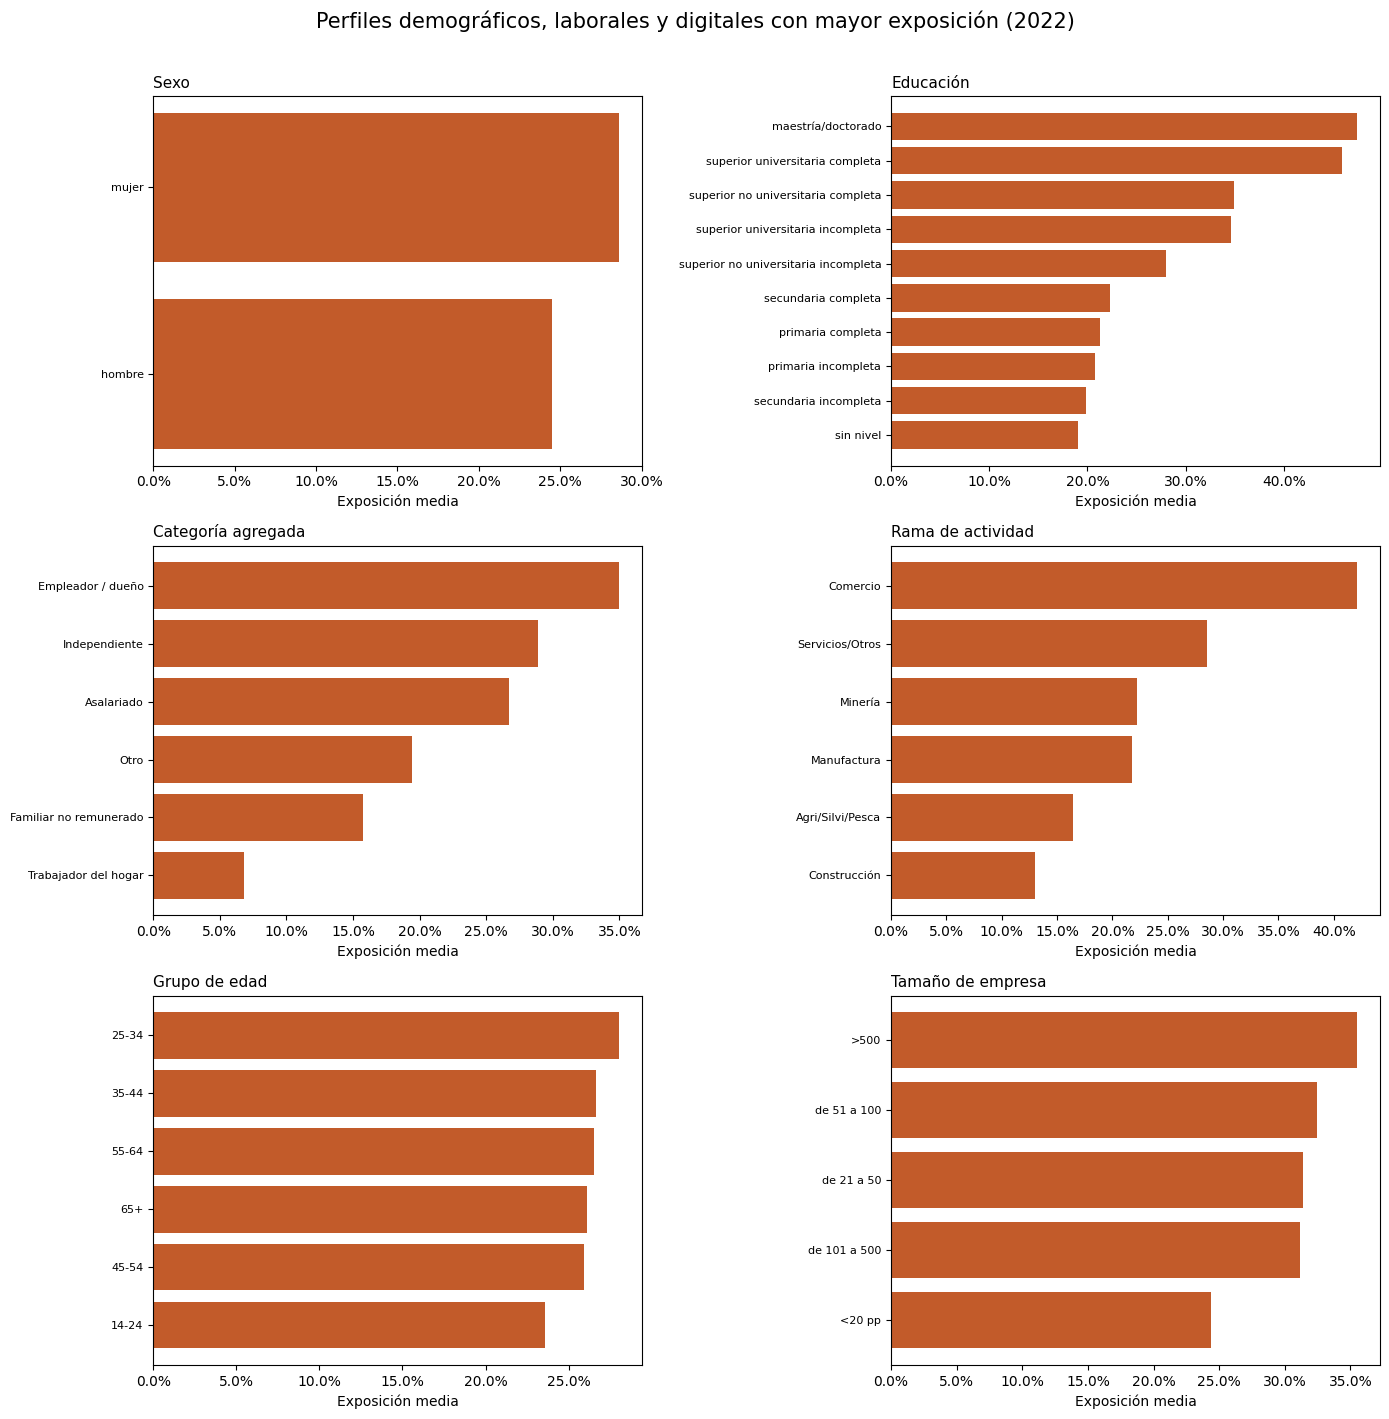

,Sexo,trabajadores,exposicion_media,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
0,hombre,9.872925e+06,0.245212,0.114313,0.007076,0.242752,0.563948
1,mujer,7.633864e+06,0.286008,0.177568,0.008149,0.331644,0.436052


,Educación,trabajadores,exposicion_media,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
0,secundaria completa,5.658547e+06,0.223092,0.107186,0.003505,0.212552,0.323723
1,secundaria incompleta,2.346628e+06,0.198663,0.088018,0.001123,0.182083,0.134250
2,primaria incompleta,1.762482e+06,0.207348,0.072160,0.000525,0.180949,0.100831
3,primaria completa,1.727365e+06,0.212575,0.081385,0.000590,0.190097,0.098822
4,superior no universitaria completa,1.727002e+06,0.349317,0.222103,0.020782,0.411107,0.098801
5,superior universitaria completa,1.474458e+06,0.459541,0.342757,0.028539,0.635871,0.084353
6,superior no universitaria incompleta,1.006013e+06,0.280052,0.161455,0.008203,0.308594,0.057554
7,superior universitaria incompleta,9.893686e+05,0.345712,0.234519,0.017608,0.407567,0.056601
8,sin nivel,4.929193e+05,0.189939,0.066109,0.000300,0.158113,0.028200
9,maestría/doctorado,2.947912e+05,0.474105,0.291337,0.013136,0.706981,0.016865


,Categoría agregada,trabajadores,exposicion_media,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
0,Asalariado,8.135104e+06,0.267175,0.145156,0.011089,0.297557,0.464683
1,Independiente,6.661459e+06,0.289159,0.148080,0.001773,0.299014,0.380507
2,Familiar no remunerado,1.663675e+06,0.157288,0.090566,0.000693,0.168035,0.095030
3,Empleador / dueño,5.915968e+05,0.349610,0.271908,0.048854,0.379363,0.033792
4,Trabajador del hogar,4.152465e+05,0.068305,0.000000,0.000000,0.004949,0.023719
5,Otro,3.970751e+04,0.194310,0.133812,0.000061,0.247587,0.002268


,Rama de actividad,trabajadores,exposicion_media,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
0,Servicios/Otros,6.524974e+06,0.285440,0.173241,0.014967,0.308229,0.372711
1,Agri/Silvi/Pesca,4.417020e+06,0.164113,0.017966,0.000273,0.103280,0.252303
2,Comercio,3.462769e+06,0.420777,0.309347,0.005186,0.571528,0.197796
3,Manufactura,1.551286e+06,0.217808,0.078257,0.006746,0.198688,0.088611
4,Construcción,1.330676e+06,0.130071,0.047465,0.003033,0.092267,0.076009
5,Minería,2.200628e+05,0.222236,0.084632,0.003408,0.231557,0.012570


,Grupo de edad,trabajadores,exposicion_media,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
0,25-34,4.290869e+06,0.280262,0.164514,0.009985,0.316918,0.245097
1,35-44,3.907388e+06,0.266231,0.143614,0.008549,0.284662,0.223193
2,45-54,3.172192e+06,0.259440,0.129072,0.006353,0.269676,0.181198
3,14-24,2.874243e+06,0.235895,0.135403,0.005920,0.252338,0.164179
4,55-64,2.065489e+06,0.265370,0.135387,0.007017,0.272928,0.117982
5,65+,1.196608e+06,0.261025,0.115997,0.003481,0.260557,0.068351


,Tamaño de empresa,trabajadores,exposicion_media,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
0,<20 pp,1.399044e+07,0.244014,0.127284,0.004744,0.251831,0.799144
1,>500,2.050208e+06,0.354780,0.206279,0.020268,0.425452,0.117109
2,de 21 a 50,5.588054e+05,0.314232,0.195244,0.015353,0.366910,0.031919
3,de 101 a 500,5.534520e+05,0.311701,0.182485,0.017411,0.351485,0.031614
4,de 51 a 100,3.538822e+05,0.324881,0.198802,0.016768,0.376809,0.020214


,Uso de internet en el trabajo,trabajadores,exposicion_media,pct_media_alta_exp,pct_alta_exposicion,pct_aumento,pct_sustitucion,population_share
0,no usa internet en el trabajo,1.205262e+07,0.264102,0.288606,0.146982,0.285634,0.007069,0.688454
1,sin dato,4.361821e+06,0.205315,0.177154,0.070928,0.176692,0.000654,0.249150
2,usa internet en el trabajo,1.092349e+06,0.481203,0.671009,0.369155,0.654616,0.040297,0.062396


,Frecuencia de uso de internet en el trabajo,trabajadores,exposicion_media,pct_media_alta_exp,pct_alta_exposicion,pct_aumento,pct_sustitucion,population_share
0,no usa internet en el trabajo,1.641444e+07,0.248480,0.258990,0.126772,0.256684,0.005365,0.937604
1,una vez al día,1.082434e+06,0.481957,0.672839,0.369739,0.656471,0.040079,0.061829
2,una vez a la semana,9.914831e+03,0.398866,0.471161,0.305404,0.452106,0.064055,0.000566


,Categoría ocupacional,trabajadores,exposicion_media,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
0,trabajador independiente,6.661459e+06,0.289159,0.148080,0.001773,0.299014,0.380507
1,obrero,4.310695e+06,0.107272,0.008283,0.000103,0.038256,0.246230
2,empleado,3.824409e+06,0.447411,0.299431,0.023471,0.589829,0.218453
3,trabajador familiar no remunerado,1.663675e+06,0.157288,0.090566,0.000693,0.168035,0.095030
4,empleador o patrono,5.915968e+05,0.349610,0.271908,0.048854,0.379363,0.033792
5,trabajador del hogar,4.152465e+05,0.068305,0.000000,0.000000,0.004949,0.023719
6,otro,3.970751e+04,0.194310,0.133812,0.000061,0.247587,0.002268


,Contrato,trabajadores,exposicion_media,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
0,Sin dato,7.253056e+06,0.294090,0.158180,0.005613,0.305568,0.414300
1,sin contrato,6.260031e+06,0.168210,0.074627,0.002058,0.160617,0.357577
2,plazo fijo,2.292884e+06,0.334594,0.204416,0.015519,0.394594,0.130971
3,indefinido,1.052324e+06,0.391294,0.242228,0.026593,0.478016,0.060110
4,locacion de servicios,4.008012e+05,0.346178,0.202478,0.019057,0.415415,0.022894
5,CAS,1.820285e+05,0.405582,0.248852,0.032298,0.525828,0.010398
6,practicas preprof,4.567090e+04,0.425032,0.293565,0.020009,0.595972,0.002609
7,periodo de prueba,1.990672e+04,0.367231,0.311899,0.024325,0.472895,0.001137
8,otro,8.607066e+01,0.050000,0.000000,0.000000,0.000000,0.000005


,Estrato,trabajadores,exposicion_media,pct_alta_exposicion,pct_sustitucion,pct_aumento,population_share
0,1,6.433638e+06,0.303734,0.187095,0.011531,0.347384,0.367494
1,5,2.785628e+06,0.251345,0.131939,0.005900,0.266418,0.159117
2,7,2.420991e+06,0.185382,0.044733,0.000787,0.143437,0.138289
3,2,2.408579e+06,0.285910,0.170742,0.008824,0.324276,0.137580
4,4,1.267746e+06,0.250307,0.139388,0.007415,0.270219,0.072415
5,3,8.447903e+05,0.274502,0.167782,0.008279,0.310387,0.048255
6,8,8.137735e+05,0.182594,0.039502,0.000464,0.138136,0.046483
7,6,5.316423e+05,0.215899,0.080421,0.002864,0.199051,0.030368


In [9]:
primary_sheets = ["sexo", "educacion", "categoria_agregada", "rama", "grupo_edad", "formalidad_tamano"]
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for ax, sheet_name in zip(axes, primary_sheets):
    df = profile_tables[sheet_name].sort_values("mean_exposure_score", ascending=True).copy()
    ax.barh(df["group"], df["mean_exposure_score"], color=COLORS["accent"])
    ax.set_title(PROFILE_LABELS[sheet_name], fontsize=11, loc="left")
    ax.set_xlabel("Exposición media")
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.tick_params(axis="y", labelsize=8)

for ax in axes[len(primary_sheets):]:
    ax.axis("off")

fig.suptitle(f"Perfiles demográficos, laborales y digitales con mayor exposición ({ANALYSIS_YEAR})", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

profile_plot_order = [
    "sexo",
    "educacion",
    "categoria_agregada",
    "rama",
    "grupo_edad",
    "formalidad_tamano",
    "internet_uso",
    "internet_frecuencia",
    "categoria",
    "formalidad_contrato",
    "estrato",
]

for sheet_name in profile_plot_order:
    df = profile_tables[sheet_name].copy().sort_values("weighted_population", ascending=False).reset_index(drop=True)
    label = PROFILE_LABELS.get(sheet_name, sheet_name)
    horizontal = (len(df) > 6) or (df["group"].astype(str).str.len().max() > 18)
    display(
        df.rename(
            columns={
                "group": label,
                "weighted_population": "trabajadores",
                "mean_exposure_score": "exposicion_media",
                "pct_aumento": "pct_aumento",
                "pct_sustitucion": "pct_sustitucion",
            }
        )
    )
    if HAS_PLOTLY:
        plot_df = df.sort_values("mean_exposure_score", ascending=horizontal).copy()
        if horizontal:
            fig = px.bar(
                plot_df,
                x="mean_exposure_score",
                y="group",
                orientation="h",
                color="pct_aumento",
                color_continuous_scale=["#1d4ed8", "#0891b2", "#10b981", "#f59e0b"],
                hover_data={"weighted_population": ":,.0f", "pct_sustitucion": ":.1%", "population_share": ":.1%"},
                labels={"group": label, "mean_exposure_score": "Exposición media", "pct_aumento": "% aumento"},
            )
            fig.update_layout(title=f"Exposición media por {label.lower()} ({ANALYSIS_YEAR})", height=520)
        else:
            fig = px.bar(
                plot_df,
                x="group",
                y="mean_exposure_score",
                color="pct_aumento",
                color_continuous_scale=["#1d4ed8", "#0891b2", "#10b981", "#f59e0b"],
                hover_data={"weighted_population": ":,.0f", "pct_sustitucion": ":.1%", "population_share": ":.1%"},
                labels={"group": label, "mean_exposure_score": "Exposición media", "pct_aumento": "% aumento"},
            )
            fig.update_layout(title=f"Exposición media por {label.lower()} ({ANALYSIS_YEAR})", xaxis_tickangle=-25, height=500)
        show_plotly(fig)
    else:
        fig, ax = plt.subplots(figsize=(11, 5))
        if horizontal:
            plot_df = df.sort_values("mean_exposure_score", ascending=True)
            ax.barh(plot_df["group"], plot_df["mean_exposure_score"], color=COLORS["accent"])
            ax.set_ylabel(label)
            ax.xaxis.set_major_formatter(PercentFormatter(1.0))
        else:
            ax.bar(df["group"], df["mean_exposure_score"], color=COLORS["accent"])
            ax.tick_params(axis="x", rotation=25)
            ax.set_xlabel(label)
            ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.set_title(f"Exposición media por {label.lower()} ({ANALYSIS_YEAR})")
        ax.set_ylabel("Exposición media")
        plt.tight_layout()
        plt.show()

## 7. Boxplots ponderados por dimensión

In [10]:
box_dimensions = [
    ("sex_label", "Sexo"),
    ("education_label_base", "Educación"),
    ("category_group_label", "Categoría agregada"),
    ("rama_label", "Rama de actividad"),
    ("firm_size_label", "Tamaño de empresa"),
    ("internet_use_label", "Uso de internet en el trabajo"),
]
box_metric_specs = [
    ("mean_exposure_score", "Exposición media", COLORS["accent"]),
    ("%_media_alta_exp", "% media/alta exposición", COLORS["accent2"]),
    ("%_aumento", "% aumento", COLORS["accent3"]),
    ("%_sustitucion", "% sustitución", COLORS["yellow"]),
]
weighted_box_table = build_weighted_box_table(matched_base, box_dimensions, box_metric_specs, weight_col="factor")
display(weighted_box_table.head(30))

for _, dim_label in box_dimensions:
    dim_df = weighted_box_table[weighted_box_table["dimension_label"] == dim_label].copy()
    if dim_df.empty:
        continue
    if HAS_PLOTLY and make_subplots is not None:
        fig = make_subplots(
            rows=2,
            cols=2,
            subplot_titles=[metric_label for _, metric_label, _ in box_metric_specs],
            vertical_spacing=0.12,
            horizontal_spacing=0.08,
        )
        for idx_metric, (metric_col, metric_label, color) in enumerate(box_metric_specs, start=1):
            row = 1 + (idx_metric - 1) // 2
            col = 1 + (idx_metric - 1) % 2
            sub = dim_df[dim_df["metric"] == metric_col].sort_values("p50").copy()
            for _, rec in sub.iterrows():
                fig.add_trace(
                    go.Scatter(
                        x=[rec["p05"], rec["p95"]],
                        y=[rec["group"], rec["group"]],
                        mode="lines",
                        line=dict(color=COLORS["slate"], width=2),
                        showlegend=False,
                        hoverinfo="skip",
                    ),
                    row=row,
                    col=col,
                )
                fig.add_trace(
                    go.Scatter(
                        x=[rec["p25"], rec["p75"]],
                        y=[rec["group"], rec["group"]],
                        mode="lines",
                        line=dict(color=color, width=10),
                        showlegend=False,
                        hovertemplate=f"{dim_label}<br>Grupo: {rec['group']}<br>Rango intercuartílico: %{{x:.1%}}<extra></extra>",
                    ),
                    row=row,
                    col=col,
                )
                fig.add_trace(
                    go.Scatter(
                        x=[rec["p50"]],
                        y=[rec["group"]],
                        mode="markers",
                        marker=dict(color=COLORS["text"], size=7),
                        showlegend=False,
                        hovertemplate=f"{dim_label}<br>Grupo: {rec['group']}<br>Mediana ponderada: %{{x:.1%}}<extra></extra>",
                    ),
                    row=row,
                    col=col,
                )
            fig.update_xaxes(tickformat=".0%", row=row, col=col)
        fig.update_layout(
            title=f"Boxplots ponderados por {dim_label.lower()} ({ANALYSIS_YEAR})",
            height=860,
            margin=dict(l=10, r=10, t=70, b=20),
        )
        show_plotly(fig)
    else:
        display(dim_df.sort_values(["metric_label", "p50"], ascending=[True, False]))

,dimension,dimension_label,group,metric,metric_label,weighted_population,p05,p25,p50,p75,p95
0,sex_label,Sexo,hombre,mean_exposure_score,Exposición media,9.872925e+06,0.0500,0.078300,0.237500,0.316700,0.599300
1,sex_label,Sexo,hombre,%_media_alta_exp,% media/alta exposición,9.872925e+06,0.0000,0.000000,0.166700,0.333300,1.000000
2,sex_label,Sexo,hombre,%_aumento,% aumento,9.872925e+06,0.0000,0.000000,0.166700,0.333300,1.000000
3,sex_label,Sexo,hombre,%_sustitucion,% sustitución,9.872925e+06,0.0000,0.000000,0.000000,0.000000,0.000000
4,sex_label,Sexo,mujer,mean_exposure_score,Exposición media,7.633864e+06,0.0500,0.062500,0.266700,0.442500,0.600700
5,sex_label,Sexo,mujer,%_media_alta_exp,% media/alta exposición,7.633864e+06,0.0000,0.000000,0.222200,0.666700,1.000000
6,sex_label,Sexo,mujer,%_aumento,% aumento,7.633864e+06,0.0000,0.000000,0.222200,0.600000,1.000000
7,sex_label,Sexo,mujer,%_sustitucion,% sustitución,7.633864e+06,0.0000,0.000000,0.000000,0.000000,0.000000
8,education_label_base,Educación,Sin dato,mean_exposure_score,Exposición media,8.909780e+03,0.0500,0.085955,0.264728,0.370335,0.410348
9,education_label_base,Educación,Sin dato,%_media_alta_exp,% media/alta exposición,8.909780e+03,0.0000,0.000000,0.000000,0.517220,0.607337


## 8. Estadística exploratoria por cruces

In [11]:
spearman_rows = []
kruskal_rows = []

if HAS_SCIPY:
    occ_pairs = [
        ("pct_aumento", "Exposición vs % aumento"),
        ("pct_sustitucion", "Exposición vs % sustitución"),
        ("share_women", "Exposición vs proporción de mujeres"),
        ("mean_age", "Exposición vs edad media ocupacional"),
        ("weighted_population", "Exposición vs tamaño del empleo"),
    ]
    for other_col, label in occ_pairs:
        valid = occupation_summary[["mean_exposure_score", other_col]].dropna().copy()
        if len(valid) >= 3:
            rho, p_value = spearmanr(valid["mean_exposure_score"], valid[other_col])
            spearman_rows.append({"pair": label, "n": int(len(valid)), "rho": float(rho), "p_value": float(p_value)})

    valid_income = income_df[["mean_exposure_score", "income_monthly_weighted_mean"]].dropna().copy()
    if len(valid_income) >= 3:
        rho, p_value = spearmanr(valid_income["mean_exposure_score"], valid_income["income_monthly_weighted_mean"])
        spearman_rows.append({"pair": "Exposición vs ingreso medio ocupacional", "n": int(len(valid_income)), "rho": float(rho), "p_value": float(p_value)})

    kruskal_specs = [
        ("sex_label", "Sexo"),
        ("education_label_base", "Educación"),
        ("category_group_label", "Categoría agregada"),
        ("rama_label", "Rama de actividad"),
        ("internet_use_label", "Uso de internet en el trabajo"),
        ("internet_frequency_label", "Frecuencia de internet en el trabajo"),
    ]
    for col, label in kruskal_specs:
        sub = matched_base[[col, "mean_exposure_score"]].dropna().copy()
        counts = sub[col].value_counts()
        valid_groups = counts[counts >= 30].index.tolist()
        arrays = [sub.loc[sub[col] == group_name, "mean_exposure_score"].to_numpy() for group_name in valid_groups]
        if len(arrays) >= 2:
            stat, p_value = kruskal(*arrays)
            kruskal_rows.append(
                {
                    "dimension": label,
                    "groups_tested": len(valid_groups),
                    "n": int(sub[sub[col].isin(valid_groups)].shape[0]),
                    "statistic": float(stat),
                    "p_value": float(p_value),
                }
            )
else:
    render_note("SciPy no está disponible en este entorno. El bloque de estadística exploratoria se omite, pero el resto del notebook sigue siendo reproducible.", tone="blue")

stats_spearman = pd.DataFrame(spearman_rows)
stats_kruskal = pd.DataFrame(kruskal_rows)

render_note(
    "Las pruebas de Spearman y Kruskal se reportan como chequeo exploratorio. Los gráficos principales y las tablas sustantivas siguen siendo ponderados; estas pruebas no aplican directamente pesos complejos.",
    tone="blue",
)

display(stats_spearman)
display(stats_kruskal)

,pair,n,rho,p_value
0,Exposición vs % aumento,391,0.928851,7.507624e-170
1,Exposición vs % sustitución,391,0.309296,4.097505e-10
2,Exposición vs proporción de mujeres,391,0.064336,2.042966e-01
3,Exposición vs edad media ocupacional,391,-0.117612,2.000519e-02
4,Exposición vs tamaño del empleo,391,-0.198612,7.679428e-05
5,Exposición vs ingreso medio ocupacional,67,0.403479,7.101762e-04


,dimension,groups_tested,n,statistic,p_value
0,Sexo,2,59711,280.403571,6.132695e-63
1,Educación,11,59675,10454.064046,0.000000e+00
2,Categoría agregada,6,59711,9216.349446,0.000000e+00
3,Rama de actividad,6,59711,16443.185470,0.000000e+00
4,Uso de internet en el trabajo,3,59711,5186.510494,0.000000e+00
5,Frecuencia de internet en el trabajo,3,59711,4068.007475,0.000000e+00


## 9. Curvas acumuladas por población

In [12]:
cumulative_frames = []
concentration_rows = []
for metric_col, metric_label, _ in [
    ("mean_exposure_score", "Exposición media", COLORS["accent"]),
    ("pct_aumento", "% aumento", COLORS["accent3"]),
    ("pct_sustitucion", "% sustitución", COLORS["yellow"]),
]:
    curve = build_cumulative_curve(occupation_summary, metric_col, metric_label)
    if curve.empty:
        continue
    cumulative_frames.append(curve)
    for threshold in [0.10, 0.25, 0.50]:
        reached = curve[curve["cum_population_share"] >= threshold]
        if reached.empty:
            continue
        concentration_rows.append(
            {
                "metric_label": metric_label,
                "top_population_share": threshold,
                "cum_metric_share": float(reached.iloc[0]["cum_metric_share"]),
            }
        )

cumulative_df = pd.concat(cumulative_frames, ignore_index=True) if cumulative_frames else pd.DataFrame()
concentration_df = pd.DataFrame(concentration_rows)
display(concentration_df)

if HAS_PLOTLY and not cumulative_df.empty:
    fig = px.line(
        cumulative_df,
        x="cum_population_share",
        y="cum_metric_share",
        color="metric_label",
        hover_data={"occupation_group": True, "weighted_population": ":,.0f"},
        labels={
            "cum_population_share": "Participación acumulada de trabajadores",
            "cum_metric_share": "Participación acumulada del indicador",
            "metric_label": "Métrica",
        },
        color_discrete_map={
            "Exposición media": COLORS["accent"],
            "% aumento": COLORS["accent3"],
            "% sustitución": COLORS["yellow"],
        },
    )
    fig.add_shape(
        type="line",
        x0=0,
        y0=0,
        x1=1,
        y1=1,
        line=dict(color=COLORS["slate"], dash="dash"),
    )
    fig.update_layout(
        title=f"Curvas acumuladas por población ocupada ({ANALYSIS_YEAR})",
        height=620,
        margin=dict(l=10, r=10, t=60, b=20),
    )
    fig.update_xaxes(tickformat=".0%")
    fig.update_yaxes(tickformat=".0%")
    show_plotly(fig)
elif not cumulative_df.empty:
    fig, ax = plt.subplots(figsize=(9, 6))
    for metric_label, color in [("Exposición media", COLORS["accent"]), ("% aumento", COLORS["accent3"]), ("% sustitución", COLORS["yellow"])]:
        sub = cumulative_df[cumulative_df["metric_label"] == metric_label]
        if sub.empty:
            continue
        ax.plot(sub["cum_population_share"], sub["cum_metric_share"], label=metric_label, color=color)
    ax.plot([0, 1], [0, 1], linestyle="--", color=COLORS["slate"])
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f"Curvas acumuladas por población ocupada ({ANALYSIS_YEAR})")
    ax.legend()
    plt.tight_layout()
    plt.show()

,metric_label,top_population_share,cum_metric_share
0,Exposición media,0.10,0.296791
1,Exposición media,0.25,0.522831
2,Exposición media,0.50,0.814668
3,% aumento,0.10,0.356496
4,% aumento,0.25,0.777511
5,% aumento,0.50,0.998588
6,% sustitución,0.10,1.000000
7,% sustitución,0.25,1.000000
8,% sustitución,0.50,1.000000


## 10. Extremos de exposición dentro de cada dimensión

In [13]:
comparison_df["dimension_label"] = comparison_df["dimension"].map(PROFILE_LABELS).fillna(comparison_df["dimension"])
comparison_view = comparison_df[
    [
        "dimension_label",
        "top_group",
        "top_exposure",
        "bottom_group",
        "bottom_exposure",
        "gap_exposure",
    ]
].rename(
    columns={
        "dimension_label": "dimension",
        "top_group": "mayor_exposicion",
        "top_exposure": "score_mayor",
        "bottom_group": "menor_exposicion",
        "bottom_exposure": "score_menor",
        "gap_exposure": "brecha",
    }
)
display(comparison_view)

if HAS_PLOTLY:
    fig = px.bar(
        comparison_df.sort_values("gap_exposure"),
        x="gap_exposure",
        y="dimension_label",
        orientation="h",
        color="gap_exposure",
        color_continuous_scale=["#93c5fd", "#c25b2a"],
        custom_data=["top_group", "bottom_group", "top_exposure", "bottom_exposure"],
        labels={"gap_exposure": "Brecha de exposición", "dimension_label": "Dimensión"},
    )
    fig.update_traces(
        hovertemplate="<b>%{y}</b><br>Mayor exposición: %{customdata[0]} (%{customdata[2]:.1%})<br>"
        "Menor exposición: %{customdata[1]} (%{customdata[3]:.1%})<br>"
        "Brecha: %{x:.1%}<extra></extra>"
    )
    fig.update_layout(title=f"Mayor brecha interna de exposición por dimensión ({ANALYSIS_YEAR})", height=520)
    show_plotly(fig)
else:
    ordered = comparison_df.sort_values("gap_exposure")
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(ordered["dimension_label"], ordered["gap_exposure"], color=COLORS["accent2"])
    ax.set_xlabel("Brecha de exposición")
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_ylabel("")
    ax.set_title(f"Mayor brecha interna de exposición por dimensión ({ANALYSIS_YEAR})")
    plt.tight_layout()
    plt.show()

top_gap = comparison_df.iloc[0]
render_note(
    f"La mayor brecha interna del año aparece en <strong>{top_gap['dimension_label']}</strong>: "
    f"{top_gap['top_group']} alcanza {fmt_pct(top_gap['top_exposure'])} frente a {fmt_pct(top_gap['bottom_exposure'])} en {top_gap['bottom_group']}.",
    tone="blue",
)

,dimension,mayor_exposicion,score_mayor,menor_exposicion,score_menor,brecha
0,Categoría ocupacional,empleado,0.447411,trabajador del hogar,0.068305,0.379105
1,Contrato,practicas preprof,0.425032,otro,0.050000,0.375032
2,Rama de actividad,Comercio,0.420777,Construcción,0.130071,0.290706
3,Educación,maestría/doctorado,0.474105,sin nivel,0.189939,0.284166
4,Categoría agregada,Empleador / dueño,0.349610,Trabajador del hogar,0.068305,0.281305
5,Uso de internet en el trabajo,usa internet en el trabajo,0.481203,sin dato,0.205315,0.275887
6,Frecuencia de uso de internet en el trabajo,una vez al día,0.481957,no usa internet en el trabajo,0.248480,0.233477
7,Estrato,1.0,0.303734,8.0,0.182594,0.121140
8,Tamaño de empresa,>500,0.354780,<20 pp,0.244014,0.110767
9,Grupo de edad,25-34,0.280262,14-24,0.235895,0.044367


## 11. Ingresos y exposición

In [14]:
render_cards(
    [
        {
            "label": "Correlación ingreso-exposición",
            "value": f"{income_corr:.2f}" if pd.notna(income_corr) else "N/D",
            "sub": "Correlación entre ingreso mensual medio y score ocupacional",
        },
        {
            "label": "Ocupaciones en scatter",
            "value": fmt_num(len(income_df)),
            "sub": "Solo ocupaciones ENAHO con más de 50 mil ocupados e ingreso reportado",
        },
        {
            "label": "Ingreso medio máximo",
            "value": fmt_sol(income_df['income_monthly_weighted_mean'].max()),
            "sub": "Máximo ingreso promedio ocupacional del corte anual",
        },
    ]
)

if HAS_PLOTLY:
    fig = px.scatter(
        income_df,
        x="mean_exposure_score",
        y="income_monthly_weighted_mean",
        size="weighted_population",
        color="women_share_weighted",
        color_continuous_scale=["#2563eb", "#f59e0b", "#c25b2a"],
        hover_name="occupation_name_cno",
        hover_data={
            "occupation_code_4d": True,
            "income_monthly_weighted_mean": ":,.0f",
            "income_monthly_median_weighted": ":,.0f",
            "weighted_population": ":,.0f",
            "women_share_weighted": ":.1%",
        },
        labels={
            "mean_exposure_score": "Exposición media",
            "income_monthly_weighted_mean": "Ingreso mensual medio",
            "women_share_weighted": "Proporción de mujeres",
        },
        size_max=44,
    )
    fig.update_layout(
        title=f"Ingreso laboral mensual y exposición a IA ({ANALYSIS_YEAR})",
        height=620,
        margin=dict(l=10, r=10, t=60, b=20),
    )
    show_plotly(fig)
else:
    fig, ax = plt.subplots(figsize=(10, 7))
    sizes = np.sqrt(income_df["weighted_population"] / income_df["weighted_population"].max()) * 1400
    scatter = ax.scatter(
        income_df["mean_exposure_score"],
        income_df["income_monthly_weighted_mean"],
        s=sizes,
        c=income_df["women_share_weighted"],
        cmap="plasma",
        alpha=0.75,
        edgecolors="white",
        linewidth=0.6,
    )
    ax.set_xlabel("Exposición media")
    ax.set_ylabel("Ingreso mensual medio")
    ax.yaxis.set_major_formatter(StrMethodFormatter("S/ {x:,.0f}"))
    ax.set_title(f"Ingreso laboral mensual y exposición a IA ({ANALYSIS_YEAR})")
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label("Proporción de mujeres")
    plt.tight_layout()
    plt.show()

display(
    income_df[
        [
            "occupation_code_4d",
            "occupation_name_cno",
            "weighted_population",
            "income_monthly_weighted_mean",
            "income_monthly_median_weighted",
            "mean_exposure_score",
        ]
    ]
    .sort_values(["mean_exposure_score", "income_monthly_weighted_mean"], ascending=[False, False])
    .head(20)
)

render_note(
    f"Chequeo de ingresos extremos en microdatos armonizados del año: {outliers_over_20k} casos por encima de S/ 20 mil y {outliers_over_50k} por encima de S/ 50 mil.",
    tone="green",
)

,occupation_code_4d,occupation_name_cno,weighted_population,income_monthly_weighted_mean,income_monthly_median_weighted,mean_exposure_score
15,4312,"Empleados de servicios estadísticos, financier...",6.254132e+04,2560.768667,2213.0,0.7775
14,4222,Empleados de centros de llamadas,5.064951e+04,1267.372537,1104.0,0.7025
25,5243,Vendedores por teléfono,5.576432e+04,595.076222,300.0,0.6808
10,3314,Técnicos en administración,2.290949e+05,2082.731031,1700.0,0.6725
4,2411,Contadores,7.124777e+04,3228.567706,2700.0,0.6713
12,4110,Jefes de empleados administrativos,1.284789e+05,3356.945215,2500.0,0.6333
17,4417,"Auxiliares en la administración, contabilidad,...",6.351105e+04,1372.111923,1200.0,0.6007
22,5212,Vendedores minoristas en tiendas y establecimi...,1.341564e+06,965.720417,960.0,0.5993
3,2359,Otros profesionales de la enseñanza,5.964276e+04,1326.829067,1095.0,0.5800
13,4120,Secretarios,6.623862e+04,1468.397892,1273.0,0.5467


## 12. Perfiles del trabajador expuesto

In [15]:
def weighted_mode(series, weights):
    valid = pd.DataFrame({"value": series, "weight": weights}).dropna()
    if valid.empty:
        return "N/D"
    return valid.groupby("value")["weight"].sum().sort_values(ascending=False).index[0]

def build_persona(df, label, tier):
    if df.empty:
        return None
    weights = df["weight"]
    total = weights.sum()
    occ_top = (
        df.groupby(["occupation_code_4d", "occupation_group"], dropna=False)["weight"]
        .sum()
        .sort_values(ascending=False)
        .head(3)
    )
    top_occupations = [
        {
            "code": code,
            "name": str(name)[:62] if pd.notna(name) else "N/D",
            "workers": float(workers),
        }
        for (code, name), workers in occ_top.items()
    ]
    income_valid = df[df["labor_income_monthly"].notna()].copy()
    return {
        "label": label,
        "tier": tier,
        "total_workers": float(total),
        "mean_exposure": weighted_mean(df["mean_exposure_score"], weights),
        "pct_aumento": weighted_mean(df["%_aumento"], weights),
        "pct_sustitucion": weighted_mean(df["%_sustitucion"], weights),
        "pct_women": weighted_share(df["sex"].astype(str).eq("Mujer"), weights),
        "pct_urban": weighted_mean(df["is_urban"], weights),
        "mean_age": weighted_mean(df["age"], weights),
        "income_mean": weighted_mean(income_valid["labor_income_monthly"], income_valid["weight"]),
        "top_category": weighted_mode(df["category_label"], weights),
        "top_education": weighted_mode(df["education_label"], weights),
        "top_occupations": top_occupations,
    }

persona_records = [
    build_persona(persona_q4, f"Perú {ANALYSIS_YEAR} — alta exposición (Q4)", "alta"),
    build_persona(persona_q1, f"Perú {ANALYSIS_YEAR} — baja exposición (Q1)", "baja"),
]

for region_code, region_name in PERSONA_REGIONS:
    sub = enaho_micro[pd.to_numeric(enaho_micro["region_code"], errors="coerce") == region_code].copy()
    if len(sub) < 40:
        continue
    q75_region = sub["mean_exposure_score"].quantile(0.75)
    persona_records.append(
        build_persona(sub[sub["mean_exposure_score"] >= q75_region], f"{region_name} {ANALYSIS_YEAR} — alta exposición (Q4)", "alta")
    )

persona_records = [p for p in persona_records if p is not None]
persona_export = pd.DataFrame(
    [
        {
            k: json.dumps(v, ensure_ascii=False) if isinstance(v, list) else v
            for k, v in persona.items()
        }
        for persona in persona_records
    ]
)

cards = []
for persona in persona_records:
    occ_html = "".join(
        [
            f"<li><span class='mini-tag'>{o['code']}</span>{o['name']} ({fmt_num(o['workers'])})</li>"
            for o in persona["top_occupations"]
        ]
    )
    cards.append(
        f'''
        <div class="audit-card">
          <div class="eyebrow">{persona['label']}</div>
          <div class="value">{fmt_pct(persona['mean_exposure'])}</div>
          <div class="sub">{persona['top_category']} · {persona['top_education']}</div>
          <div style="margin-top:10px;font-size:12px;color:{COLORS['muted']};">
            Mujeres: {fmt_pct(persona['pct_women'])} · Urbano: {fmt_pct(persona['pct_urban'])} · Edad media: {persona['mean_age']:.1f}
          </div>
          <div style="margin-top:6px;font-size:12px;color:{COLORS['muted']};">
            Ingreso mensual: {fmt_sol(persona['income_mean'])} · Augmentation: {fmt_pct(persona['pct_aumento'])}
          </div>
          <ul style="margin:10px 0 0 18px;padding:0;font-size:12px;color:{COLORS['text']};">{occ_html}</ul>
        </div>
        '''
    )
display(HTML("<div class='audit-grid'>" + "".join(cards) + "</div>"))

persona_compare = pd.DataFrame(
    [
        {"metric": "Mujeres", "Q4": persona_records[0]["pct_women"], "Q1": persona_records[1]["pct_women"]},
        {"metric": "Urbano", "Q4": persona_records[0]["pct_urban"], "Q1": persona_records[1]["pct_urban"]},
        {"metric": "Augmentation", "Q4": persona_records[0]["pct_aumento"], "Q1": persona_records[1]["pct_aumento"]},
        {"metric": "Sustitución", "Q4": persona_records[0]["pct_sustitucion"], "Q1": persona_records[1]["pct_sustitucion"]},
    ]
)

if HAS_PLOTLY:
    fig = go.Figure()
    fig.add_bar(name="Q4 alta exposición", x=persona_compare["metric"], y=persona_compare["Q4"], marker_color=COLORS["accent"])
    fig.add_bar(name="Q1 baja exposición", x=persona_compare["metric"], y=persona_compare["Q1"], marker_color=COLORS["accent2"])
    fig.update_layout(
        title=f"Comparación de perfiles del trabajador expuesto ({ANALYSIS_YEAR})",
        barmode="group",
        yaxis_tickformat=".0%",
        height=460,
    )
    show_plotly(fig)
else:
    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(persona_compare))
    width = 0.35
    ax.bar(x - width / 2, persona_compare["Q4"], width, label="Q4 alta exposición", color=COLORS["accent"])
    ax.bar(x + width / 2, persona_compare["Q1"], width, label="Q1 baja exposición", color=COLORS["accent2"])
    ax.set_xticks(x)
    ax.set_xticklabels(persona_compare["metric"])
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f"Comparación de perfiles del trabajador expuesto ({ANALYSIS_YEAR})")
    ax.legend()
    plt.tight_layout()
    plt.show()

persona_export

,label,tier,total_workers,mean_exposure,pct_aumento,pct_sustitucion,pct_women,pct_urban,mean_age,income_mean,top_category,top_education,top_occupations
0,Perú 2022 — alta exposición (Q4),alta,5.263578e+06,0.512968,0.745829,0.025092,0.559483,0.933153,39.320492,2066.313910,Empleado/a,N/D,"[{""code"": ""5212"", ""name"": ""Vendedores minorist..."
1,Perú 2022 — baja exposición (Q1),baja,4.162362e+06,0.051234,0.000000,0.000000,0.477200,0.632244,37.183922,980.109613,Obrero/a,N/D,"[{""code"": ""9211"", ""name"": ""Peones de explotaci..."
2,Lima 2022 — alta exposición (Q4),alta,1.413845e+06,0.589273,0.884715,0.043468,0.494638,0.995097,39.249454,2431.483494,Empleado/a,N/D,"[{""code"": ""5212"", ""name"": ""Vendedores minorist..."
3,Arequipa 2022 — alta exposición (Q4),alta,1.908398e+05,0.569473,0.856749,0.040014,0.519703,0.968503,39.788153,2241.453430,Empleado/a,N/D,"[{""code"": ""5212"", ""name"": ""Vendedores minorist..."
4,La Libertad 2022 — alta exposición (Q4),alta,2.505667e+05,0.550012,0.822274,0.031891,0.506822,0.943112,37.825910,1749.897282,Empleado/a,N/D,"[{""code"": ""5212"", ""name"": ""Vendedores minorist..."
5,Callao 2022 — alta exposición (Q4),alta,1.265596e+05,0.606841,0.909833,0.042924,0.581028,1.000000,37.648555,1936.887840,Empleado/a,N/D,"[{""code"": ""5212"", ""name"": ""Vendedores minorist..."


## 13. Análisis departamental

In [16]:
if regional_df.empty:
    render_note(
        f"No hay corte EPEN anual disponible para {ANALYSIS_YEAR}. El bloque departamental solo puede replicarse desde 2022 en adelante.",
        tone="blue",
    )
else:
    render_cards(
        [
            {
                "label": "Departamentos con dato",
                "value": fmt_num(len(regional_df)),
                "sub": "EPEN anual con match ocupacional e ingreso mensual",
            },
            {
                "label": "Mayor exposición departamental",
                "value": fmt_pct(regional_df['mean_exposure'].max()),
                "sub": str(regional_df.iloc[0]["region_name"]),
            },
            {
                "label": "Ingreso departamental más alto",
                "value": fmt_sol(regional_df['income_mean'].max()),
                "sub": str(regional_df.sort_values('income_mean', ascending=False).iloc[0]["region_name"]),
            },
        ]
    )

    if HAS_PLOTLY:
        fig = px.bar(
            regional_df.sort_values("mean_exposure"),
            x="mean_exposure",
            y="region_name",
            orientation="h",
            color="income_mean",
            color_continuous_scale=["#bfdbfe", "#2563eb"],
            hover_data={"workers": ":,.0f", "pct_alta": ":.1%", "pct_aumento": ":.1%"},
            labels={"mean_exposure": "Exposición media", "region_name": "Departamento", "income_mean": "Ingreso medio"},
        )
        fig.update_layout(title=f"Exposición a IA por departamento ({ANALYSIS_YEAR})", height=700)
        show_plotly(fig)
    else:
        ordered = regional_df.sort_values("mean_exposure")
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.barh(ordered["region_name"], ordered["mean_exposure"], color=COLORS["accent2"])
        ax.xaxis.set_major_formatter(PercentFormatter(1.0))
        ax.set_title(f"Exposición a IA por departamento ({ANALYSIS_YEAR})")
        ax.set_xlabel("Exposición media")
        plt.tight_layout()
        plt.show()

    regional_occ_view = (
        regional_top_occ.sort_values(["region_code", "mean_exposure"], ascending=[True, False])
        .groupby("region_code")
        .head(3)
        .merge(regional_df[["region_code", "region_name"]], how="left", on="region_code")
    )
    display(
        regional_occ_view[
            ["region_name", "occupation_code_4d", "occupation_group", "workers", "mean_exposure"]
        ].rename(
            columns={
                "region_name": "departamento",
                "occupation_code_4d": "cno_4d",
                "occupation_group": "ocupacion",
                "workers": "trabajadores",
                "mean_exposure": "exposicion_media",
            }
        )
    )

,departamento,cno_4d,ocupacion,trabajadores,exposicion_media
0,Amazonas,5212,Vendedores minoristas en tiendas y establecimi...,11163.835446,0.5993
1,Amazonas,6122,Avicultores y trabajadores calificados de la a...,16025.671914,0.3333
2,Amazonas,6112,Agricultores y trabajadores calificados de pla...,15611.767204,0.2905
3,Ancash,5212,Vendedores minoristas en tiendas y establecimi...,34592.316398,0.5993
4,Ancash,5120,Cocineros,19042.334883,0.3300
5,Ancash,6121,Criadores y trabajadores calificados de ganado,19224.412305,0.2750
6,Apurímac,5212,Vendedores minoristas en tiendas y establecimi...,13185.748575,0.5993
7,Apurímac,6114,Agricultores y trabajadores calificados de cul...,51299.852042,0.2639
8,Apurímac,9313,Peones de la construcción de edificios,10100.019506,0.0500
9,Arequipa,3314,Técnicos en administración,16968.443298,0.6725


## 14. Auditoría anual de coherencia

In [17]:
calc_coverage = matched_base["factor"].sum() / base["factor"].sum()
calc_mean_exposure = weighted_mean(matched_base["mean_exposure_score"], matched_base["factor"])
calc_pct_alta = weighted_mean(matched_base["%_alta_exposicion"], matched_base["factor"])
calc_pct_aumento = weighted_mean(matched_base["%_aumento"], matched_base["factor"])
calc_pct_sustitucion = weighted_mean(matched_base["%_sustitucion"], matched_base["factor"])

audit_frame = pd.DataFrame(
    [
        {
            "analysis_year": ANALYSIS_YEAR,
            "coverage_report": coverage["cobertura_ponderada"],
            "coverage_rebuilt": calc_coverage,
            "coverage_diff": abs(calc_coverage - coverage["cobertura_ponderada"]),
            "mean_exposure_report": coverage["media_exposicion_ponderada"],
            "mean_exposure_rebuilt": calc_mean_exposure,
            "mean_exposure_diff": abs(calc_mean_exposure - coverage["media_exposicion_ponderada"]),
            "pct_alta_report": coverage["media_pct_alta_ponderada"],
            "pct_alta_rebuilt": calc_pct_alta,
            "pct_aumento_report": coverage["media_pct_aumento_ponderada"],
            "pct_aumento_rebuilt": calc_pct_aumento,
            "pct_sustitucion_report": coverage["media_pct_sustitucion_ponderada"],
            "pct_sustitucion_rebuilt": calc_pct_sustitucion,
            "unmatched_occupations": len(unmatched_occ),
            "outliers_over_20k": outliers_over_20k,
            "outliers_over_50k": outliers_over_50k,
        }
    ]
)

render_cards(
    [
        {
            "label": "Diferencia cobertura",
            "value": f"{audit_frame.iloc[0]['coverage_diff']:.6f}",
            "sub": "Reporte anual vs reconstrucción desde microdatos",
        },
        {
            "label": "Diferencia exposición media",
            "value": f"{audit_frame.iloc[0]['mean_exposure_diff']:.6f}",
            "sub": "Debe tender a cero si no hay contradicción interna",
        },
        {
            "label": "Ocupaciones fuera del índice",
            "value": fmt_num(len(unmatched_occ)),
            "sub": f"{fmt_num(unmatched_occ['weighted_population'].sum())} ocupados ponderados sin score",
        },
        {
            "label": "Atípicos de ingreso >50k",
            "value": fmt_num(outliers_over_50k),
            "sub": f"{fmt_num(outliers_over_20k)} casos por encima de 20k",
        },
    ]
)

if audit_frame.iloc[0]["coverage_diff"] < 1e-9 and audit_frame.iloc[0]["mean_exposure_diff"] < 1e-9:
    render_note("La reconstrucción desde microdatos replica exactamente los indicadores de cobertura y exposición media del reporte anual. No se detectaron contradicciones internas en estas métricas.", tone="green")
else:
    render_note("La auditoría encontró diferencias no triviales entre el reporte anual y la reconstrucción desde microdatos. Este caso requiere revisar el pipeline antes de usar resultados externos.", tone="amber")

display(
    unmatched_occ.head(15).rename(
        columns={
            "occupation_code_4d": "cno_4d",
            "weighted_population": "trabajadores",
            "occupation_name_cno": "ocupacion",
            "reason": "motivo",
        }
    )
)

audit_frame

,cno_4d,trabajadores,ocupacion,motivo
0,4419,233890.964306,Otro personal de apoyo administrativo,Sin score en índice IA
1,0220,71950.860084,Suboficiales de la Policía Nacional,Sin score en índice IA
2,7399,46321.044377,Otros Artesanos y trabajadores en la elaboraci...,Sin score en índice IA
3,3439,39018.166956,Otros profesionales técnicos en actividades cu...,Sin score en índice IA
4,7129,25447.246528,Otros pintores excepto brocha gorda,Sin score en índice IA
5,7519,18027.031978,Otros trabajadores de la preparación de alimen...,Sin score en índice IA
6,3149,11595.501072,Otros técnicos en control de procesos,Sin score en índice IA
7,3129,11306.174607,"Otros supervisores en ingeniería de minas, de ...",Sin score en índice IA
8,8189,10351.480983,Otros Operadores de máquinas y de instalacione...,Sin score en índice IA
9,0312,6999.104883,Técnicos de la Marina de Guerra,Sin score en índice IA


,analysis_year,coverage_report,coverage_rebuilt,coverage_diff,mean_exposure_report,mean_exposure_rebuilt,mean_exposure_diff,pct_alta_report,pct_alta_rebuilt,pct_aumento_report,pct_aumento_rebuilt,pct_sustitucion_report,pct_sustitucion_rebuilt,unmatched_occupations,outliers_over_20k,outliers_over_50k
0,2022,0.972599,0.972599,0.0,0.263001,0.263001,5.551115e-17,0.141895,0.141895,0.281514,0.281514,0.007544,0.007544,23,5,0


## 15. Exportación de tablas auxiliares

In [18]:
export_map = {
    f"coverage_{ANALYSIS_YEAR}.csv": pd.DataFrame([coverage]),
    f"distribution_summary_{ANALYSIS_YEAR}.csv": distribution_summary,
    f"occupation_summary_{ANALYSIS_YEAR}.csv": occupation_summary,
    f"top_occupations_{ANALYSIS_YEAR}.csv": top_occ,
    f"top_exposed_mass_{ANALYSIS_YEAR}.csv": top_exposed_mass,
    f"transform_scatter_{ANALYSIS_YEAR}.csv": transform_df,
    f"bubble_occupations_{ANALYSIS_YEAR}.csv": bubble_df,
    f"treemap_occupations_{ANALYSIS_YEAR}.csv": treemap_df,
    f"comparison_{ANALYSIS_YEAR}.csv": comparison_df,
    f"weighted_boxplots_{ANALYSIS_YEAR}.csv": weighted_box_table,
    f"stats_spearman_{ANALYSIS_YEAR}.csv": stats_spearman,
    f"stats_kruskal_{ANALYSIS_YEAR}.csv": stats_kruskal,
    f"cumulative_curves_{ANALYSIS_YEAR}.csv": cumulative_df,
    f"cumulative_concentration_{ANALYSIS_YEAR}.csv": concentration_df,
    f"income_scatter_{ANALYSIS_YEAR}.csv": income_df,
    f"personas_{ANALYSIS_YEAR}.csv": persona_export,
    f"regional_{ANALYSIS_YEAR}.csv": regional_df,
    f"regional_top_occ_{ANALYSIS_YEAR}.csv": regional_top_occ,
    f"unmatched_occupations_{ANALYSIS_YEAR}.csv": unmatched_occ,
    f"audit_{ANALYSIS_YEAR}.csv": audit_frame,
}

for sheet_name, df in profile_tables.items():
    export_map[f"profile_{sheet_name}_{ANALYSIS_YEAR}.csv"] = df

for filename, df in export_map.items():
    df.to_csv(OUTPUT_TABLES / filename, index=False)

with (OUTPUT_TABLES / f"audit_summary_{ANALYSIS_YEAR}.json").open("w", encoding="utf-8") as fh:
    json.dump(audit_summary, fh, ensure_ascii=False, indent=2)

exported_files = sorted(p.name for p in OUTPUT_TABLES.iterdir())
print(f"Tablas exportadas en: {OUTPUT_TABLES.relative_to(PROJECT_ROOT)}")
pd.DataFrame({"archivo": exported_files})

Tablas exportadas en: _interno\outputs\enaho_exposure_2022\annual_tables


,archivo
0,audit_2022.csv
1,audit_summary_2022.json
2,bubble_occupations_2022.csv
3,comparison_2022.csv
4,coverage_2022.csv
5,cumulative_concentration_2022.csv
6,cumulative_curves_2022.csv
7,distribution_summary_2022.csv
8,income_scatter_2022.csv
9,occupation_summary_2022.csv
